<a href="https://colab.research.google.com/github/minhphu12-oc/basic-python/blob/sklearn-project-for-machine-learning/project_8_multiclass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bước 1 : Phân tích dữ liệu

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CSV = 'UNSW_NB15_training-set.csv'
df = pd.read_csv(CSV)

In [2]:
# đọc 5 dòng đầu của dữ liệu
df.head(5)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
df.shape

(175341, 45)

In [4]:
# đọc thông tin dữ liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [5]:
# tìm giá trị thiếu
df.isnull().sum()

,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


In [6]:
# đọc trạng thái
df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [7]:
# xem phân bổ các lớp (đây là nhãn cần dự đoán)
df['attack_cat'].value_counts()

,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


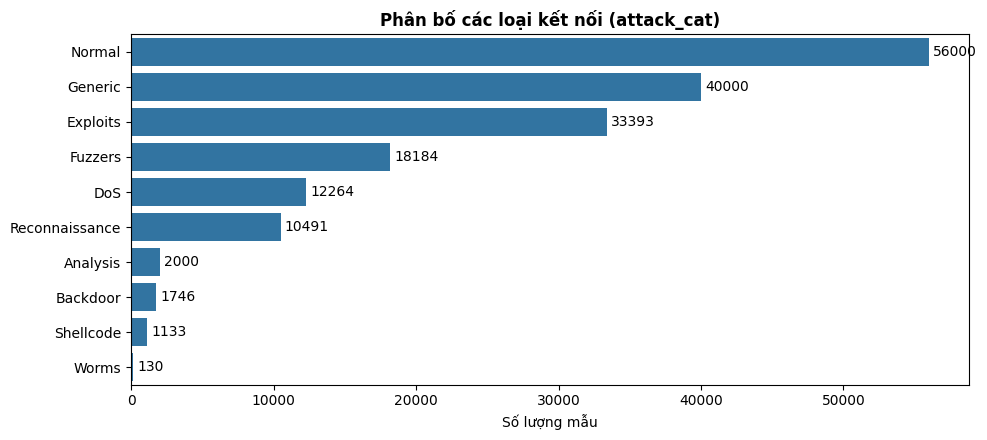

In [8]:
plt.figure(figsize=(10, 4.5))
ax = sns.countplot(data=df, y='attack_cat', order=df['attack_cat'].value_counts().index, color='#1f77b4')
ax.bar_label(ax.containers[0], padding=3)
plt.title('Phân bố các loại kết nối (attack_cat)', fontsize=12, fontweight='bold')
plt.xlabel('Số lượng mẫu')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [9]:
df['service'].value_counts()

,count
service,
-,94168
dns,47294
http,18724
smtp,5058
ftp-data,3995
ftp,3428
ssh,1302
pop3,1105
dhcp,94


In [10]:
df['is_ftp_login'].value_counts()

,count
is_ftp_login,
0,172774
1,2545
4,16
2,6


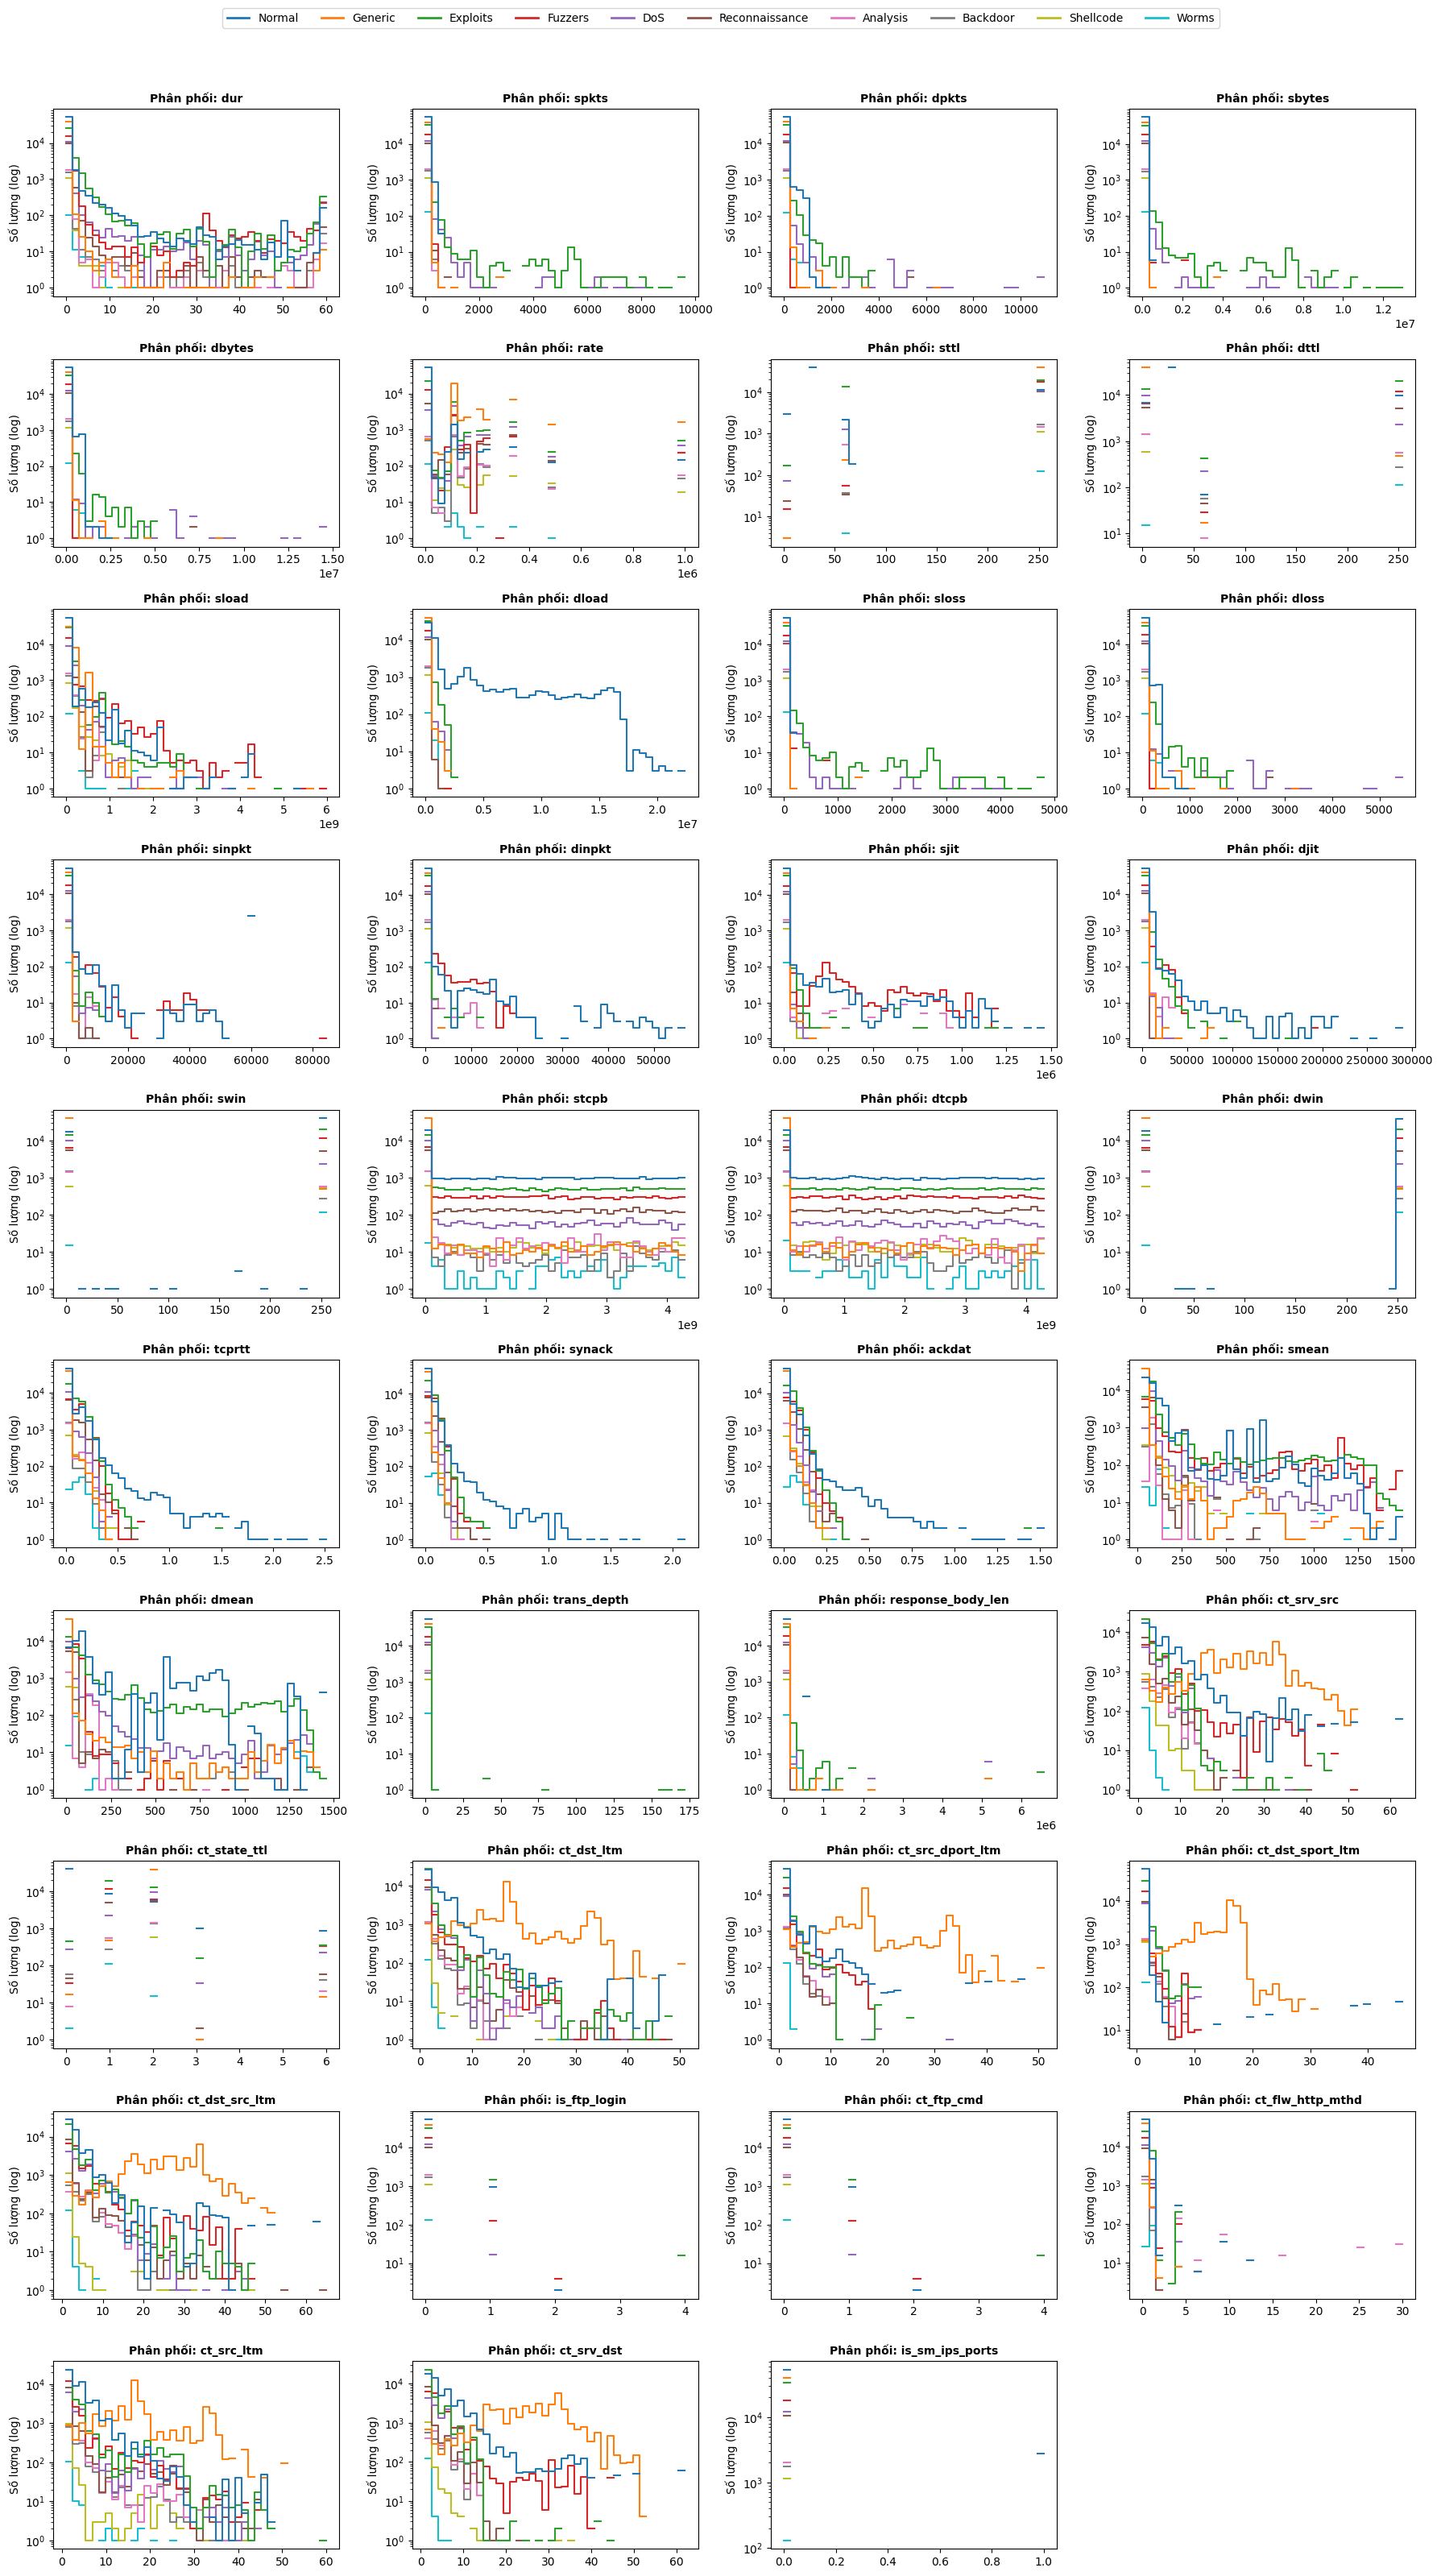

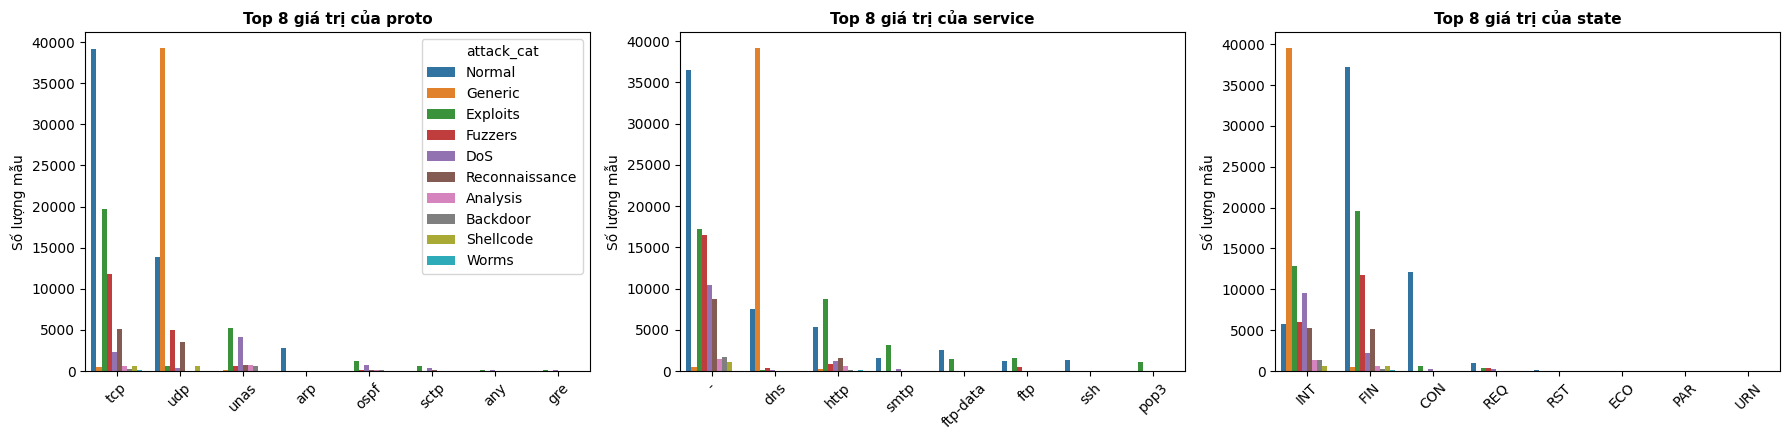

In [11]:
# vẽ sự tương quan, độ lệch giữa các feature theo từng loại kết nối
from matplotlib.lines import Line2D

cats = df['attack_cat'].value_counts().index.tolist()
palette = dict(zip(cats, sns.color_palette('tab10', n_colors=len(cats))))

num_cols_eda = df.select_dtypes(include=[np.number]).drop(columns=['id', 'label']).columns

n_cols = 4
n_rows = math.ceil(len(num_cols_eda) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(num_cols_eda):
    sns.histplot(
        data=df, x=col, hue='attack_cat', hue_order=cats, bins=40, ax=axes[i],
        log_scale=(False, True), element='step', fill=False, palette=palette, legend=False
    )
    axes[i].set_title(f'Phân phối: {col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng (log)')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.legend(handles=[Line2D([0], [0], color=palette[c], lw=2, label=c) for c in cats],
           loc='upper center', ncol=len(cats), bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

cat_cols_eda = ['proto', 'service', 'state']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for i, col in enumerate(cat_cols_eda):
    top_vals = df[col].value_counts().head(8).index
    sns.countplot(
        data=df[df[col].isin(top_vals)], x=col, hue='attack_cat', hue_order=cats,
        order=top_vals, ax=axes[i], palette=palette
    )
    axes[i].set_title(f'Top 8 giá trị của {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng mẫu')
    axes[i].tick_params(axis='x', rotation=45)
    if i > 0:
        axes[i].get_legend().remove()

plt.tight_layout()
plt.show()

Bài toán phân loại đa lớp (10 lớp) trên cột `attack_cat`:

Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms

# Bước 2 : Xử lí dữ liệu

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, FunctionTransformer

df = df.dropna(subset=['attack_cat'])
df['attack_cat'] = df['attack_cat'].str.strip()

df = df.drop(columns=['id', 'label'], errors='ignore')

# Chuẩn hóa cờ nhị phân is_ftp_login (đưa giá trị > 0 về 1)
df['is_ftp_login'] = (df['is_ftp_login'] > 0).astype(int)

# Đổi ký tự '-' trong service thành 'unknown'
df['service'] = df['service'].replace('-', 'unknown')

# Loại bỏ các cột đa cộng tuyến mạnh (r > 0.96)
collinear_cols = ['ct_ftp_cmd', 'sloss', 'dloss', 'dwin', 'ct_srv_dst', 'ct_dst_src_ltm']
df = df.drop(columns=collinear_cols, errors='ignore')

# Gom nhóm các nhãn phân loại hiếm (< 100 mẫu) thành 'other'
for col in ['proto', 'service', 'state']:
    counts = df[col].value_counts()
    rare_labels = counts[counts < 100].index
    df[col] = df[col].replace(rare_labels, 'other')

x = df.drop(columns=['attack_cat'])

# mã hóa tên lớp thành số 0..9 (đúng thứ tự bảng chữ cái)
le = LabelEncoder()
y = le.fit_transform(df['attack_cat'])
class_names = list(le.classes_)
N_CLASSES = len(class_names)
print({i: c for i, c in enumerate(class_names)})

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = ['proto', 'service', 'state']
bin_cols = ['is_ftp_login', 'is_sm_ips_ports']
num_cols = [c for c in x_train.select_dtypes(include=[np.number]).columns if c not in bin_cols]

# cột lệch phải mạnh (bytes, load, rate, ...) -> log1p trước khi chuẩn hóa (chỉ dựa trên tập train)
skew = x_train[num_cols].skew()
log_cols = [c for c in num_cols if x_train[c].min() >= 0 and skew[c] > 2]
lin_cols = [c for c in num_cols if c not in log_cols]
print(f'{len(log_cols)} cột log1p + chuẩn hóa: {log_cols}')
print(f'{len(lin_cols)} cột chỉ chuẩn hóa: {lin_cols}')

preprocessor = ColumnTransformer(
    transformers=[
        ('log', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('sc', StandardScaler())]), log_cols),
        ('num', StandardScaler(), lin_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ],
    remainder='passthrough'
)

x_train = preprocessor.fit_transform(x_train)
x_test = preprocessor.transform(x_test)

{0: 'Analysis', 1: 'Backdoor', 2: 'DoS', 3: 'Exploits', 4: 'Fuzzers', 5: 'Generic', 6: 'Normal', 7: 'Reconnaissance', 8: 'Shellcode', 9: 'Worms'}
22 cột log1p + chuẩn hóa: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_flw_http_mthd']
9 cột chỉ chuẩn hóa: ['sttl', 'dttl', 'swin', 'stcpb', 'dtcpb', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_sport_ltm', 'ct_src_ltm']


In [13]:
print(x_train.shape)
print(x_test.shape)
print(pd.Series(y_train).map(dict(enumerate(class_names))).value_counts())

(140272, 150)
(35069, 150)
Normal            44800
Generic           32000
Exploits          26714
Fuzzers           14547
DoS                9811
Reconnaissance     8393
Analysis           1600
Backdoor           1397
Shellcode           906
Worms               104
Name: count, dtype: int64


# 10 Mô hình (đa lớp - tuning riêng từng mô hình + tune threshold theo lớp) :
1. logistic regression
2. bayes
3. svm
4. decision tree
5. xgboost
6. SGD classifier
7. CNN
8. MLP
9. KNN
10. Tabnet

In [14]:
!pip install -q pytorch-tabnet

import time
import itertools
import warnings
warnings.filterwarnings('ignore')
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest
from joblib import Memory
from xgboost import XGBClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch
import torch.nn as nn

# Bước 3 : Train model

**Cấu hình chung** – chỉnh ở đây:
- `FAST = True` : chạy thử nhanh (ít tổ hợp tham số, ít epoch) để kiểm tra notebook không lỗi.
- `K_LIST` : các số chiều cần so sánh (số feature được chọn / số thành phần PCA / số chiều Autoencoder).

In [15]:
FAST = False
K_LIST = [4, 8, 16]
EPOCHS = 4 if FAST else 60
AE_EPOCHS = 5 if FAST else 100


def ni(n):
  # số tổ hợp tham số thử trong RandomizedSearch (FAST thì giảm 4 lần)
  return max(2, n // 4) if FAST else n


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_GPU = torch.cuda.is_available()
NJ_XGB = 1 if USE_GPU else -1
print('device:', device, '| FAST:', FAST, '| K_LIST:', K_LIST)

device: cuda | FAST: False | K_LIST: [4, 8, 16]


3.1 Feature selection

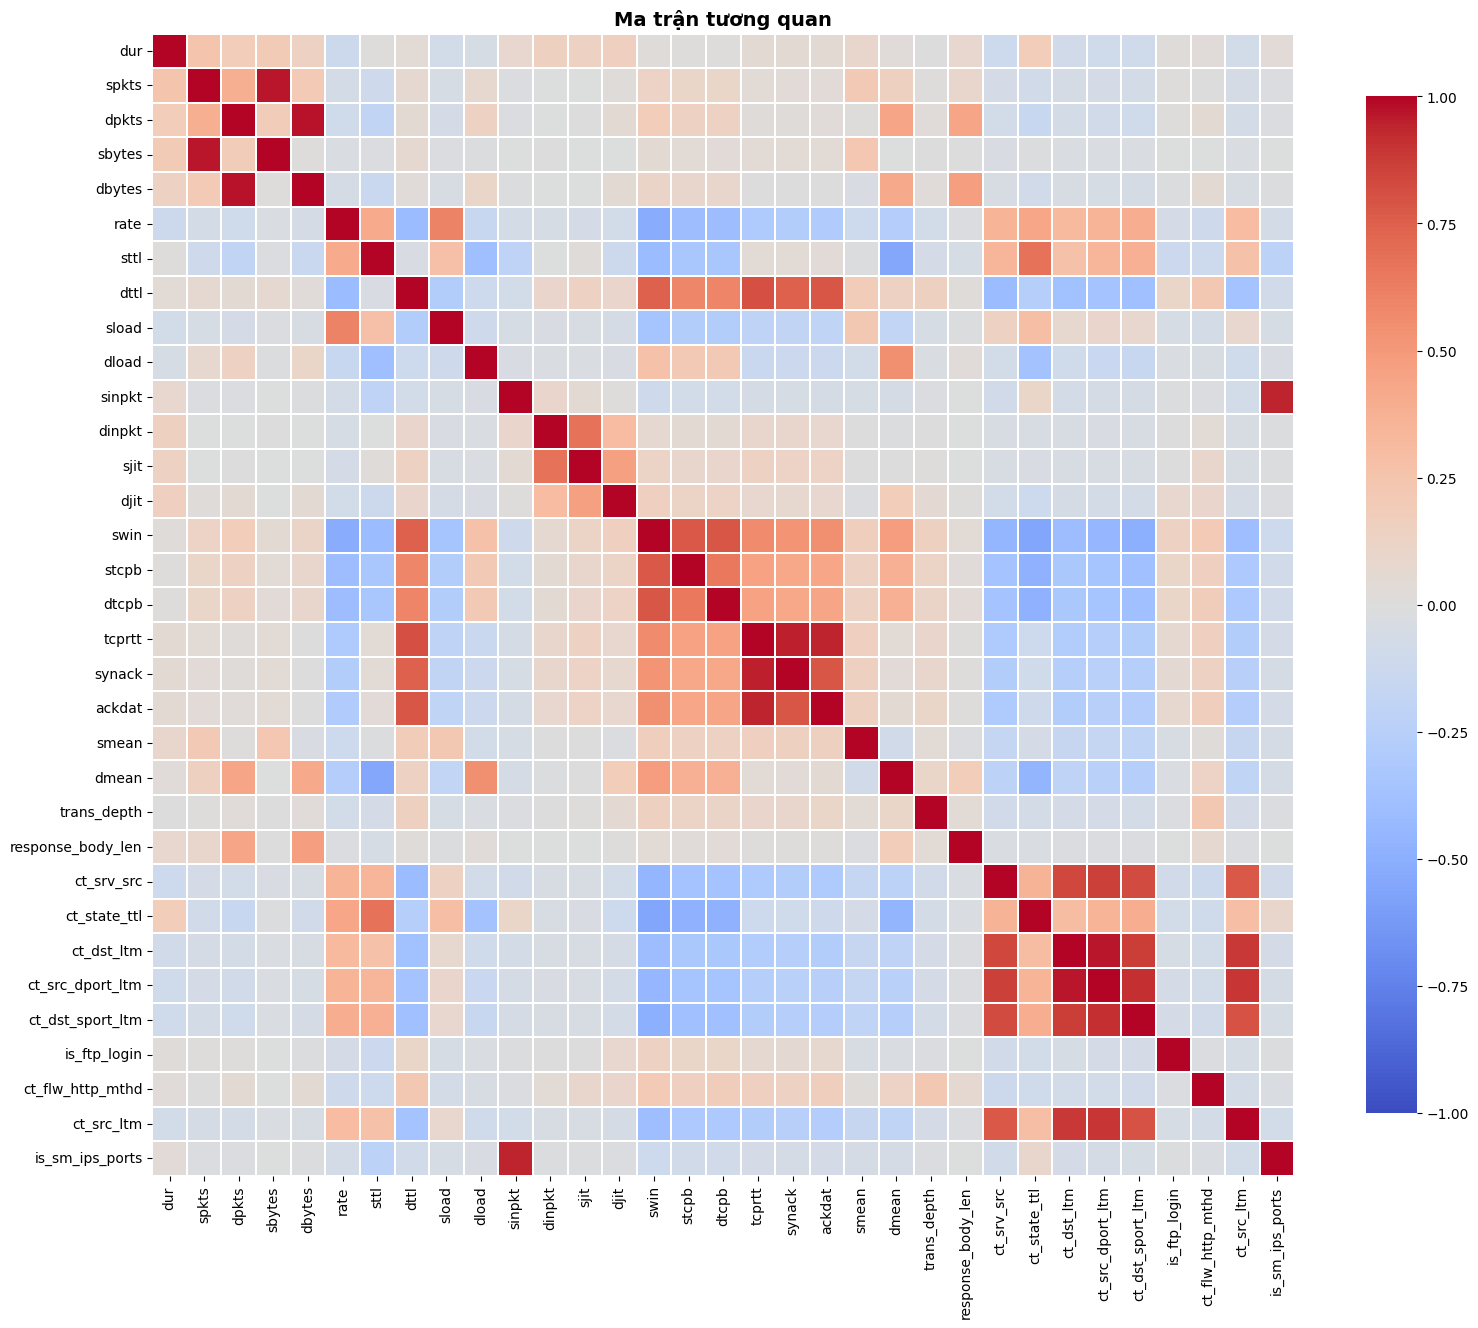

In [16]:
# vẽ ma trận tương quan
corr = df.corr(numeric_only=True)
plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.8})
plt.title('Ma trận tương quan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [28]:
y_np = np.asarray(y_train)

SVM_CAP = 5000


def cap_per_class(y, cap, seed=42):
  rng = np.random.RandomState(seed)
  keep = [rng.choice(np.where(y == c)[0], cap, replace=False) if (y == c).sum() > cap else np.where(y == c)[0]
          for c in np.unique(y)]
  return np.sort(np.concatenate(keep))


idx_svm = cap_per_class(y_np, SVM_CAP)
x_svm, y_svm = x_train[idx_svm], y_np[idx_svm]
st = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
feature_names = np.array([n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()])
du_doan_luu = {}
bias_luu = {}


# ---------- chỉ số ----------
def f1_macro_fast(y_true, y_pred):
  C = N_CLASSES
  cm = np.bincount(y_true * C + y_pred, minlength=C * C).reshape(C, C)
  tp = np.diag(cm).astype(float)
  den = cm.sum(0) + cm.sum(1)
  return float(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0).mean())


def to_log(P):
  return np.log(np.clip(P, 1e-4, 1.0))


def diem_so(model, X):
  # điểm số từng lớp: log-xác suất (SVM không có predict_proba nên dùng decision_function)
  if hasattr(model, 'predict_proba'):
    return to_log(model.predict_proba(X))
  return model.decision_function(X)


def auc_ovr(y_true, score):
  # AUC macro One-vs-Rest: tính AUC riêng cho từng lớp rồi lấy trung bình
  y_bin = label_binarize(y_true, classes=np.arange(N_CLASSES))
  aucs = [roc_auc_score(y_bin[:, c], score[:, c])
          for c in range(N_CLASSES) if 0 < y_bin[:, c].sum() < len(y_bin)]
  return float(np.mean(aucs))


def tinh_metrics(y_true, y_pred, score, y_goc=None):
  d = {
      'Accuracy': round(accuracy_score(y_true, y_pred), 4),
      'Precision': round(precision_score(y_true, y_pred, average='macro', zero_division=0), 4),
      'Recall': round(recall_score(y_true, y_pred, average='macro', zero_division=0), 4),
      'F1_Score': round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4),
  }
  if y_goc is not None:
    d['F1_Goc'] = round(f1_score(y_true, y_goc, average='macro', zero_division=0), 4)   # trước threshold
  d['F1_Weighted'] = round(f1_score(y_true, y_pred, average='weighted', zero_division=0), 4)
  d['AUC'] = round(auc_ovr(y_true, score), 4)
  return d


# ---------- tune threshold theo lớp ----------
def tune_threshold(L, y_true, rounds=3, n_grid=31):
  # tìm bias b_c cho từng lớp để F1 macro của argmax(L + b) cao nhất (coordinate ascent)
  scale = float(np.std(L)) or 1.0
  grid = np.linspace(-1.5, 1.5, n_grid) * scale
  b = np.zeros(N_CLASSES)
  best = f1_macro_fast(y_true, (L + b).argmax(1))
  for _ in range(rounds):
    improved = False
    for c in range(N_CLASSES):
      for v in grid:
        b2 = b.copy()
        b2[c] = v
        f = f1_macro_fast(y_true, (L + b2).argmax(1))
        if f > best + 1e-6:
          best, b, improved = f, b2, True
    if not improved:
      break
  return b, best


# ---------- chọn feature: xếp hạng bằng độ quan trọng ExtraTrees ----------
def rf_score(X, y):
  X, y = np.asarray(X), np.asarray(y)
  if len(X) > 60000:
    idx = np.random.RandomState(42).choice(len(X), 60000, replace=False)
    X, y = X[idx], y[idx]
  et = ExtraTreesClassifier(n_estimators=40 if FAST else 120, max_depth=16, min_samples_leaf=3,
                            max_features='sqrt', class_weight='balanced_subsample',
                            n_jobs=-1, random_state=42).fit(X, y)
  return et.feature_importances_


rf_score_cached = Memory('/tmp/fs_cache', verbose=0).cache(rf_score)


def in_feature_chon(k):
  sel = SelectKBest(rf_score_cached, k=k).fit(x_train, y_train)
  idx = np.where(sel.get_support())[0]
  idx = idx[np.argsort(-sel.scores_[idx])]
  print(f'>> {k} feature được chọn (xếp theo độ quan trọng giảm dần):')
  for r, i in enumerate(idx, 1):
    print(f'   {r:>2}. {feature_names[i]:<26} {sel.scores_[i]:.4f}')


def khong_gian_sel(k, X_a, y_a, X_b):
  sel = SelectKBest(rf_score_cached, k=k).fit(X_a, y_a)
  return sel.transform(X_a), sel.transform(X_b)


# ---------- đánh giá mô hình sklearn ----------
def oof_scores(model, X, y, n_jobs=-1):
  method = 'predict_proba' if hasattr(model, 'predict_proba') else 'decision_function'
  S = cross_val_predict(clone(model), X, y, cv=st, method=method, n_jobs=n_jobs)
  return to_log(S) if method == 'predict_proba' else S


def bang_sklearn(grid, set_k, col_k, X_tr, X_te, pp=None, ma=None, n_jobs=-1, y_tr=None, k_to_val=None):
  # Đánh giá bộ tham số tốt nhất vừa tìm được trên từng mốc k, mỗi k đều tune threshold riêng
  y_tr = y_np if y_tr is None else y_tr
  rows = []
  for k in K_LIST:
    model = clone(grid.best_estimator_).set_params(**{set_k: k if k_to_val is None else k_to_val(k)})

    t0 = time.time()
    L_oof = oof_scores(model, X_tr, y_tr, n_jobs)
    b, f1_oof = tune_threshold(L_oof, y_tr)
    thr_time = time.time() - t0

    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    t1 = time.time()
    L_te = diem_so(model, X_te)
    y_pred = (L_te + b).argmax(1)
    infer_time_ms = (time.time() - t1) * 1000
    y_goc = L_te.argmax(1)

    if pp is not None and ma is not None:
      du_doan_luu[(pp, ma, k)] = y_pred
      bias_luu[(pp, ma, k)] = b

    row = {col_k: k}
    row.update(tinh_metrics(y_test, y_pred, L_te, y_goc))
    row.update({'Train_Time_s': round(train_time, 4), 'Threshold_Time_s': round(thr_time, 2),
                'Infer_Time_ms': round(infer_time_ms, 2)})
    rows.append(row)
  return pd.DataFrame(rows)


def in_ket_qua(pp, ma, bang, col_k, best_params):
  b = bang.loc[bang['F1_Score'].idxmax()]
  k = int(b[col_k])
  print(f"k tốt nhất = {k} | F1 macro: {b['F1_Goc']} (trước threshold) -> {b['F1_Score']} (sau threshold)")
  print("Best param:", best_params)
  print("Threshold (bias) theo lớp:", dict(zip(class_names, np.round(bias_luu[(pp, ma, k)], 2).tolist())))
  if pp == "sel":
    in_feature_chon(k)
  fig, ax = plt.subplots(figsize=(8, 6))
  ConfusionMatrixDisplay(confusion_matrix(y_test, du_doan_luu[(pp, ma, k)]), display_labels=class_names).plot(
      cmap=plt.cm.Blues, xticks_rotation=45, values_format="d", ax=ax)
  ax.set_title(f"{ma} | {pp} | k={k} (sau threshold)")
  plt.tight_layout()
  plt.show()

3.1.0 Các feature được chọn theo k (xếp hạng toàn bộ feature theo độ quan trọng)

 Hang           Feature  Importance k=4 k=8 k=16
    1   service_unknown      0.0717   ✓   ✓    ✓
    2              sttl      0.0637   ✓   ✓    ✓
    3         proto_udp      0.0634   ✓   ✓    ✓
    4       service_dns      0.0629   ✓   ✓    ✓
    5  ct_src_dport_ltm      0.0574       ✓    ✓
    6      service_http      0.0423       ✓    ✓
    7             smean      0.0390       ✓    ✓
    8              dttl      0.0370       ✓    ✓
    9        ct_dst_ltm      0.0345            ✓
   10            sbytes      0.0319            ✓
   11             dmean      0.0301            ✓
   12             dload      0.0285            ✓
   13         state_INT      0.0270            ✓
   14  ct_dst_sport_ltm      0.0265            ✓
   15            dbytes      0.0260            ✓
   16        ct_srv_src      0.0238            ✓
   17              rate      0.0212             
   18      ct_state_ttl      0.0207             
   19             dpkts      0.0189             
   20             sl

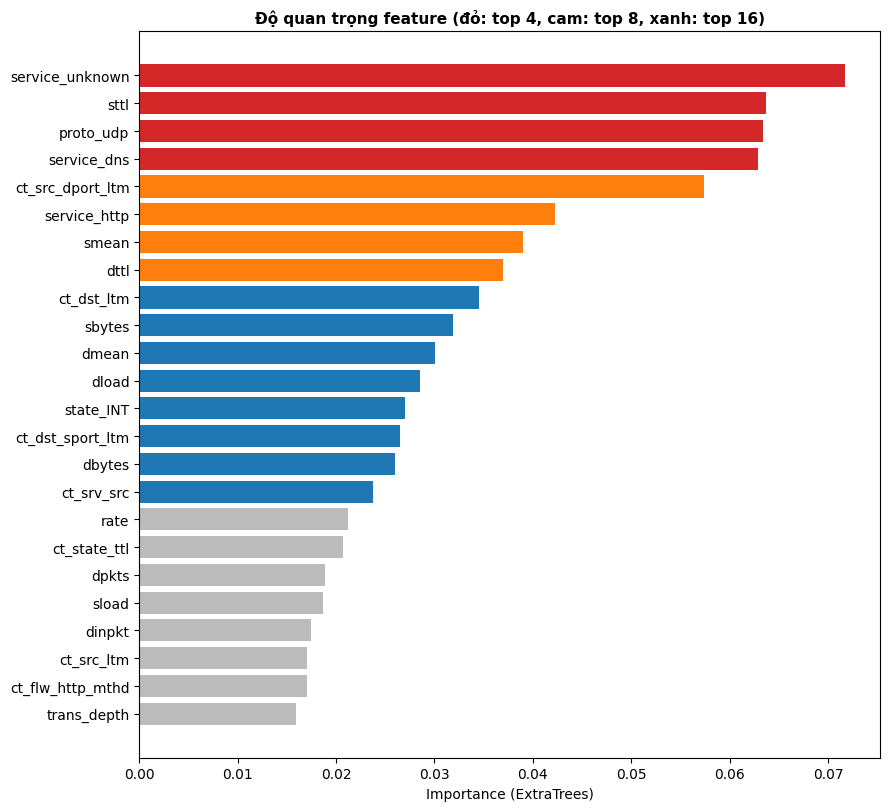


>> 4 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl                       0.0637
    3. proto_udp                  0.0634
    4. service_dns                0.0629
>> 8 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl                       0.0637
    3. proto_udp                  0.0634
    4. service_dns                0.0629
    5. ct_src_dport_ltm           0.0574
    6. service_http               0.0423
    7. smean                      0.0390
    8. dttl                       0.0370
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl                       0.0637
    3. proto_udp                  0.0634
    4. service_dns                0.0629
    5. ct_src_dport_ltm           0.0574
    6. service_http               0.0423
    7. smean                      0.0390
    8. dttl                       0.0370
    

In [18]:
sel_all = SelectKBest(rf_score_cached, k='all').fit(x_train, y_train)
imp = pd.Series(sel_all.scores_, index=feature_names).sort_values(ascending=False)

rank_df = pd.DataFrame({'Hang': np.arange(1, len(imp) + 1), 'Feature': imp.index, 'Importance': imp.values.round(4)})
for k in K_LIST:
  rank_df[f'k={k}'] = np.where(rank_df['Hang'] <= k, '✓', '')
print(rank_df.to_string(index=False))

# biểu đồ độ quan trọng, tô màu theo mốc k
top = rank_df.head(max(K_LIST) + 8).iloc[::-1]
mau_k = np.where(top['Hang'] <= K_LIST[0], '#d62728',
         np.where(top['Hang'] <= K_LIST[1], '#ff7f0e',
         np.where(top['Hang'] <= K_LIST[2], '#1f77b4', '#bbbbbb')))
plt.figure(figsize=(9, 0.28 * len(top) + 1.5))
plt.barh(top['Feature'], top['Importance'], color=mau_k)
plt.title(f'Độ quan trọng feature (đỏ: top {K_LIST[0]}, cam: top {K_LIST[1]}, xanh: top {K_LIST[2]})',
          fontsize=11, fontweight='bold')
plt.xlabel('Importance (ExtraTrees)')
plt.tight_layout()
plt.show()

print()
for k in K_LIST:
  in_feature_chon(k)

3.1.1 Logistic Regression

In [19]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', LogisticRegression(max_iter=2000, tol=1e-3, random_state=42)),
])
param_grid = [{
    'select__k': K_LIST,
    'model__C': [0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced'],
}]
grid_log = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_log.fit(x_train, y_train)
print('Best params:', grid_log.best_params_, '| CV F1 macro:', round(grid_log.best_score_, 4))

Best params: {'select__k': 16, 'model__class_weight': 'balanced', 'model__C': 1} | CV F1 macro: 0.3849


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.6281     0.3250  0.3976    0.2992  0.2294       0.6450 0.8668        3.6704              8.05          18.85
              8    0.7070     0.4644  0.5364    0.4475  0.3121       0.7199 0.9150        5.3325              8.57          28.48
             16    0.7264     0.4845  0.5814    0.4812  0.3893       0.7372 0.9357       12.2315             10.31          21.48
k tốt nhất = 16 | F1 macro: 0.3893 (trước threshold) -> 0.4812 (sau threshold)
Best param: {'select__k': 16, 'model__class_weight': 'balanced', 'model__C': 1}
Threshold (bias) theo lớp: {'Analysis': -0.64, 'Backdoor': 0.0, 'DoS': 0.32, 'Exploits': 0.0, 'Fuzzers': 0.64, 'Generic': -0.64, 'Normal': 0.0, 'Reconnaissance': 0.0, 'Shellcode': -0.64, 'Worms': -1.61}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl       

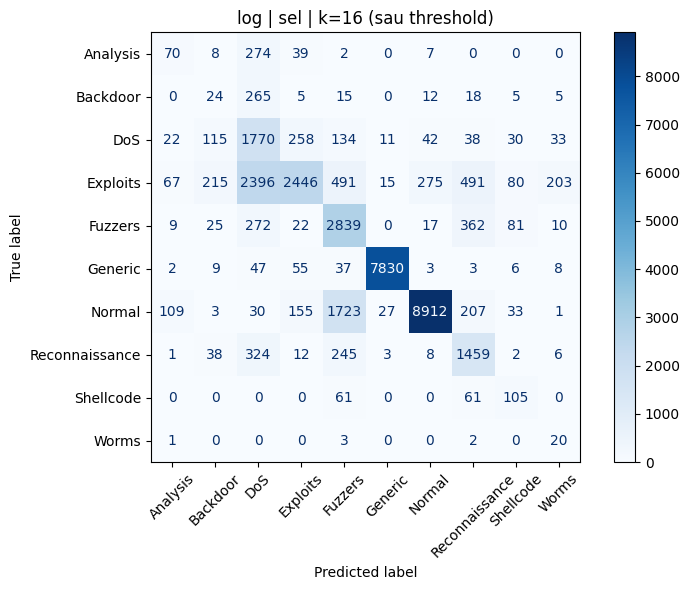

In [20]:
bang_sel_log = bang_sklearn(grid_log, 'select__k', 'So_Dac_Trung_k', x_train, x_test, pp='sel', ma='log', n_jobs=-1)
print(bang_sel_log.to_string(index=False))
in_ket_qua('sel', 'log', bang_sel_log, 'So_Dac_Trung_k', grid_log.best_params_)

3.1.2 Bayes

In [21]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', GaussianNB()),
])
param_grid = [{
    'select__k': K_LIST,
    'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3],
}]
grid_nb = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_nb.fit(x_train, y_train)
print('Best params:', grid_nb.best_params_, '| CV F1 macro:', round(grid_nb.best_score_, 4))

Best params: {'select__k': 16, 'model__var_smoothing': 0.0001} | CV F1 macro: 0.2916


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.5736     0.2944  0.3061    0.2785  0.1379       0.5892 0.8135        0.3512              7.02          24.82
              8    0.6129     0.3855  0.4150    0.3451  0.2297       0.6648 0.7840        0.3514              6.92          29.58
             16    0.5937     0.3816  0.4909    0.3452  0.2907       0.6445 0.7885        0.3813              7.26          38.07
k tốt nhất = 16 | F1 macro: 0.2907 (trước threshold) -> 0.3452 (sau threshold)
Best param: {'select__k': 16, 'model__var_smoothing': 0.0001}
Threshold (bias) theo lớp: {'Analysis': -0.91, 'Backdoor': -0.3, 'DoS': 3.35, 'Exploits': -1.83, 'Fuzzers': 4.27, 'Generic': -4.57, 'Normal': 0.0, 'Reconnaissance': 4.27, 'Shellcode': -4.57, 'Worms': -4.57}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl                     

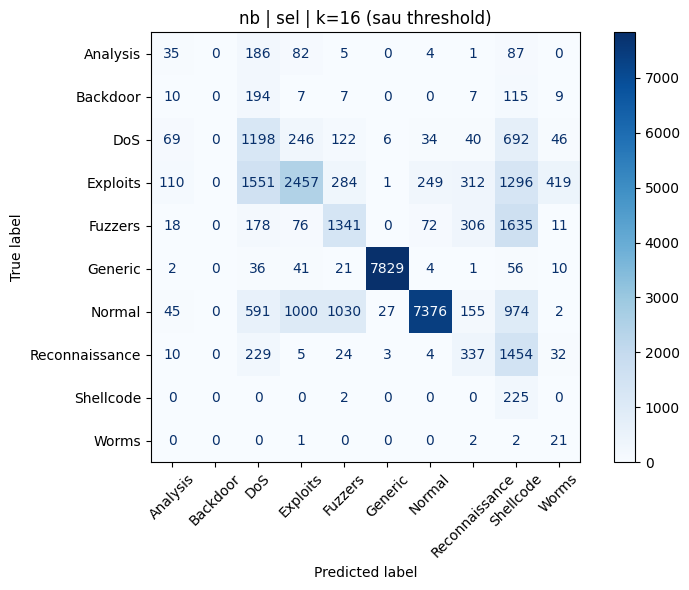

In [22]:
bang_sel_nb = bang_sklearn(grid_nb, 'select__k', 'So_Dac_Trung_k', x_train, x_test, pp='sel', ma='nb', n_jobs=-1)
print(bang_sel_nb.to_string(index=False))
in_ket_qua('sel', 'nb', bang_sel_nb, 'So_Dac_Trung_k', grid_nb.best_params_)

3.1.3 KNN

In [23]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])
param_grid = [{
    'select__k': K_LIST,
    'model__n_neighbors': [3, 5, 9, 15, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}]
grid_knn = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(12), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_knn.fit(x_train, y_train)
print('Best params:', grid_knn.best_params_, '| CV F1 macro:', round(grid_knn.best_score_, 4))

Best params: {'select__k': 8, 'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 15} | CV F1 macro: 0.5825


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.5955     0.3245  0.3313    0.2799  0.2829       0.6313 0.7750        0.4131             26.91       22907.89
              8    0.7896     0.6242  0.6011    0.5793  0.5823       0.7981 0.9164        0.5102             17.18        1930.60
             16    0.8054     0.7042  0.6241    0.6191  0.5990       0.8137 0.9159        0.3492             27.89        6496.80
k tốt nhất = 16 | F1 macro: 0.599 (trước threshold) -> 0.6191 (sau threshold)
Best param: {'select__k': 8, 'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 15}
Threshold (bias) theo lớp: {'Analysis': 0.32, 'Backdoor': 0.32, 'DoS': 0.65, 'Exploits': -0.32, 'Fuzzers': 0.0, 'Generic': 0.65, 'Normal': -0.65, 'Reconnaissance': -0.32, 'Shellcode': 0.32, 'Worms': 0.0}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.071

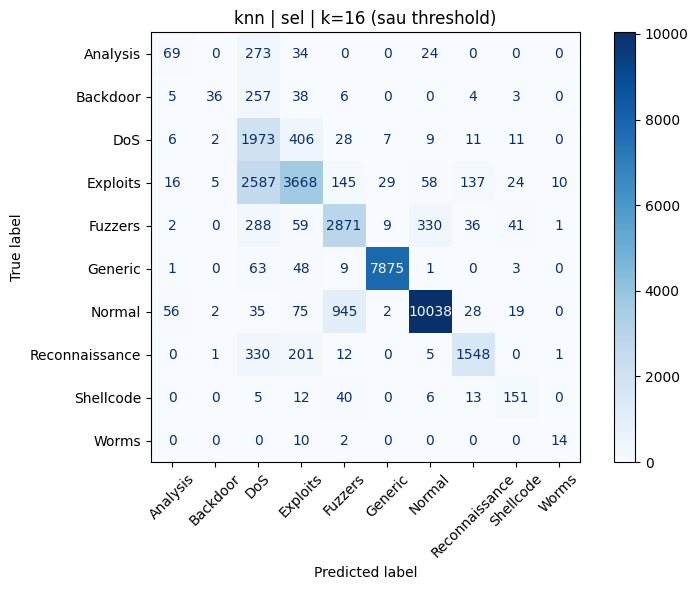

In [24]:
bang_sel_knn = bang_sklearn(grid_knn, 'select__k', 'So_Dac_Trung_k', x_train, x_test, pp='sel', ma='knn', n_jobs=-1)
print(bang_sel_knn.to_string(index=False))
in_ket_qua('sel', 'knn', bang_sel_knn, 'So_Dac_Trung_k', grid_knn.best_params_)

3.1.4 SVM

In [25]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', SVC(kernel='rbf', cache_size=2000, decision_function_shape='ovr', random_state=42)),
])
param_grid = [{
    'select__k': K_LIST,
    'model__C': [1, 5, 20],
    'model__gamma': ['scale', 0.02, 0.1],
    'model__class_weight': [None, 'balanced'],
}]
grid_svm = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(8), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_svm.fit(x_svm, y_svm)
print('Best params:', grid_svm.best_params_, '| CV F1 macro:', round(grid_svm.best_score_, 4))

Best params: {'select__k': 16, 'model__gamma': 0.1, 'model__class_weight': None, 'model__C': 20} | CV F1 macro: 0.5996


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.6295     0.3163  0.3449    0.2997  0.2997       0.6398 0.8010       27.4445             26.19       40706.69
              8    0.7389     0.4991  0.5655    0.4908  0.4854       0.7535 0.9149       42.4603             33.87       31495.27
             16    0.7578     0.5310  0.6411    0.5391  0.5542       0.7749 0.9338       41.7552             36.27       33213.66
k tốt nhất = 16 | F1 macro: 0.5542 (trước threshold) -> 0.5391 (sau threshold)
Best param: {'select__k': 16, 'model__gamma': 0.1, 'model__class_weight': None, 'model__C': 20}
Threshold (bias) theo lớp: {'Analysis': -0.31, 'Backdoor': 1.55, 'DoS': -1.24, 'Exploits': -1.24, 'Fuzzers': -0.31, 'Generic': -0.31, 'Normal': -0.31, 'Reconnaissance': -1.24, 'Shellcode': -0.31, 'Worms': 0.0}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.

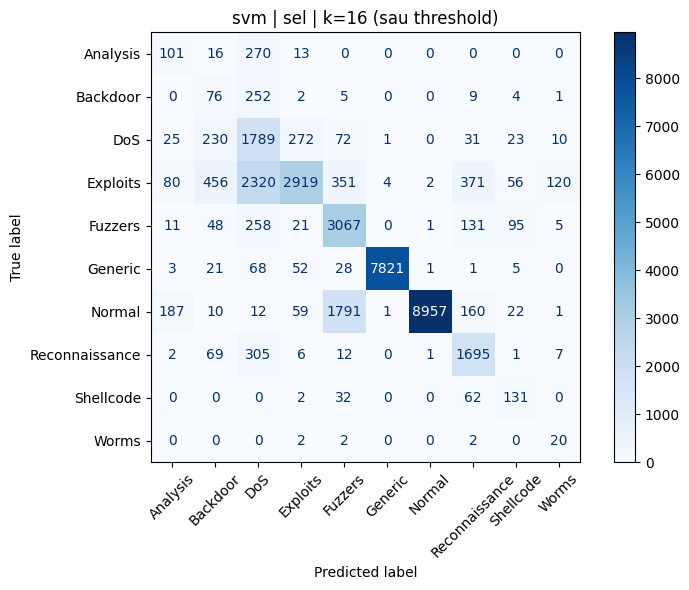

In [29]:
bang_sel_svm = bang_sklearn(grid_svm, 'select__k', 'So_Dac_Trung_k', x_svm, x_test, y_tr=y_svm, pp='sel', ma='svm', n_jobs=-1)
print(bang_sel_svm.to_string(index=False))
in_ket_qua('sel', 'svm', bang_sel_svm, 'So_Dac_Trung_k', grid_svm.best_params_)

3.1.5 DecisionTree

In [30]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', DecisionTreeClassifier(random_state=42)),
])
param_grid = [{
    'select__k': K_LIST,
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [8, 12, 16, 20, 30, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__class_weight': [None, 'balanced'],
}]
grid_dt = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(30), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_dt.fit(x_train, y_train)
print('Best params:', grid_dt.best_params_, '| CV F1 macro:', round(grid_dt.best_score_, 4))

Best params: {'select__k': 16, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 16, 'model__criterion': 'entropy', 'model__class_weight': None} | CV F1 macro: 0.5943


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.6212     0.3220  0.4178    0.3006  0.2751       0.6392 0.8832        0.3713              4.85          10.70
              8    0.7953     0.6212  0.5968    0.5850  0.5586       0.8022 0.9561        0.4127              7.53          12.08
             16    0.7965     0.6704  0.6355    0.6150  0.5895       0.8080 0.9383        1.0232              7.49          14.80
k tốt nhất = 16 | F1 macro: 0.5895 (trước threshold) -> 0.615 (sau threshold)
Best param: {'select__k': 16, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 16, 'model__criterion': 'entropy', 'model__class_weight': None}
Threshold (bias) theo lớp: {'Analysis': 0.98, 'Backdoor': 0.33, 'DoS': 0.33, 'Exploits': -0.33, 'Fuzzers': 0.0, 'Generic': -2.62, 'Normal': -0.66, 'Reconnaissance': -0.33, 'Shellcode': 0.66, 'Worms': 0.33}
>> 16 feature được ch

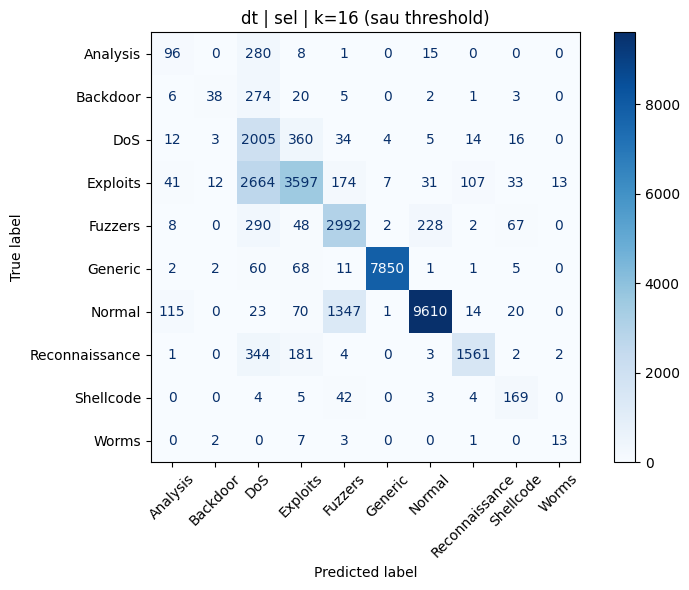

In [31]:
bang_sel_dt = bang_sklearn(grid_dt, 'select__k', 'So_Dac_Trung_k', x_train, x_test, pp='sel', ma='dt', n_jobs=-1)
print(bang_sel_dt.to_string(index=False))
in_ket_qua('sel', 'dt', bang_sel_dt, 'So_Dac_Trung_k', grid_dt.best_params_)

3.1.6 XGB

In [32]:
pipeline = Pipeline([
    ('select', SelectKBest(rf_score_cached)),
    ('model', XGBClassifier(tree_method='hist', eval_metric='mlogloss', device='cuda' if USE_GPU else 'cpu', random_state=42)),
])
param_grid = [{
    'select__k': K_LIST,
    'model__n_estimators': [200, 400, 600],
    'model__max_depth': [4, 6, 8, 10],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5],
    'model__reg_lambda': [1, 5, 10],
}]
grid_xgb = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(15), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=NJ_XGB)
grid_xgb.fit(x_train, y_train)
print('Best params:', grid_xgb.best_params_, '| CV F1 macro:', round(grid_xgb.best_score_, 4))

Best params: {'select__k': 16, 'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.8} | CV F1 macro: 0.6112


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.6444     0.3116  0.3418    0.3044  0.2751       0.6514 0.8832        3.9697             15.42         120.16
              8    0.7941     0.6204  0.5828    0.5789  0.5508       0.8009 0.9619        7.6023             28.41         171.41
             16    0.8171     0.7298  0.6599    0.6494  0.6136       0.8259 0.9670        9.9159             33.96         154.49
k tốt nhất = 16 | F1 macro: 0.6136 (trước threshold) -> 0.6494 (sau threshold)
Best param: {'select__k': 16, 'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.8}
Threshold (bias) theo lớp: {'Analysis': 1.3, 'Backdoor': 0.97, 'DoS': 0.65, 'Exploits': 0.0, 'Fuzzers': 0.0, 'Generic': -0.65, 'Normal': -0.32, 'Reconnaissance': 0.32, 'Shellcode':

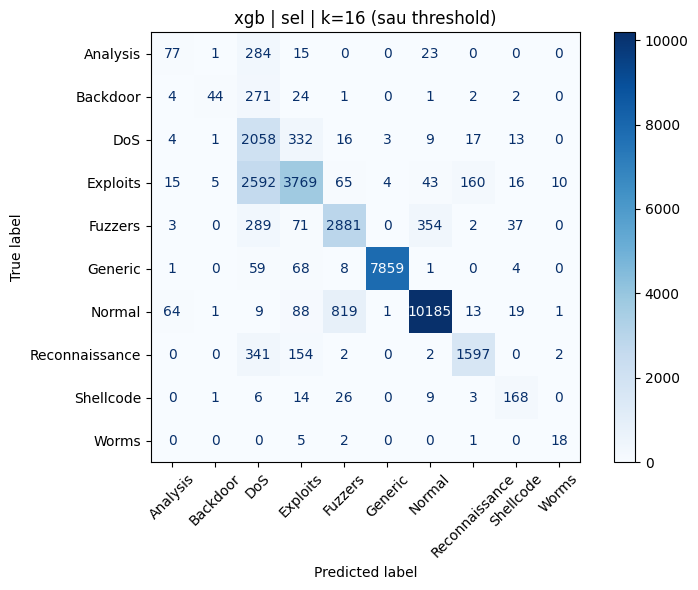

In [33]:
bang_sel_xgb = bang_sklearn(grid_xgb, 'select__k', 'So_Dac_Trung_k', x_train, x_test, pp='sel', ma='xgb', n_jobs=NJ_XGB)
print(bang_sel_xgb.to_string(index=False))
in_ket_qua('sel', 'xgb', bang_sel_xgb, 'So_Dac_Trung_k', grid_xgb.best_params_)

In [34]:
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)


class GPULoader:
  def __init__(self, *tensors, bs=1024, shuffle=True, drop_last=False):
    self.t, self.bs, self.shuffle, self.drop_last = tensors, bs, shuffle, drop_last

  def __iter__(self):
    n = len(self.t[0])
    idx = torch.randperm(n, device=self.t[0].device) if self.shuffle else torch.arange(n, device=self.t[0].device)
    for i in range(0, n, self.bs):
      j = idx[i:i + self.bs]
      if self.drop_last and len(j) < self.bs:
        break
      yield tuple(t[j] for t in self.t)


def train_es(net, opt, loader, step_loss, val_score, epochs, patience, mode):
  sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode=mode, factor=0.5, patience=2)
  sign = 1 if mode == 'max' else -1
  best, best_state, wait = None, None, 0
  for ep in range(epochs):
    net.train()
    for batch in loader:
      opt.zero_grad()
      step_loss(net, batch).backward()
      opt.step()
    net.eval()
    with torch.no_grad():
      score = val_score(net)
    sched.step(score)
    if best is None or sign * (score - best) > 1e-4:
      best, wait = score, 0
      best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
      wait += 1
      if wait >= patience:
        break
  net.load_state_dict(best_state)
  return net, best


def fit_torch_es(net, opt, X_tr, y_tr, epochs=60, patience=6, val_size=0.15, cw_pow=0.0, bs=1024):
  torch.manual_seed(42)
  y_tr = np.asarray(y_tr)
  X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=val_size, random_state=42, stratify=y_tr)
  loader = GPULoader(to_t(X_a).to(device), torch.as_tensor(y_a, dtype=torch.long, device=device),
                     bs=bs, drop_last=True)
  Xv = to_t(X_v).to(device)
  cnt = np.bincount(y_a, minlength=N_CLASSES).astype(float)
  w = (len(y_a) / (N_CLASSES * np.maximum(cnt, 1))) ** cw_pow
  crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))

  def step_loss(net, batch):
    bx, by = batch
    return crit(net(bx), by)

  def val_f1(net):
    return f1_macro_fast(y_v, net(Xv).argmax(dim=1).cpu().numpy())

  return train_es(net, opt, loader, step_loss, val_f1, epochs, patience, 'max')[0]


def fit_tabnet_es(clf, X_tr, y_tr, max_epochs=60, patience=8, val_size=0.15, weights=0):
  X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=val_size, random_state=42, stratify=y_tr)
  clf.fit(X_a, y_a, eval_set=[(X_v, y_v)], eval_name=['val'], eval_metric=['logloss'],
          max_epochs=max_epochs, patience=patience, batch_size=4096, virtual_batch_size=512, weights=weights)
  return clf


def tao_sgd(p, in_f):
  net = TorchSGD(in_f, N_CLASSES).to(device)
  return net, torch.optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=p['weight_decay'])


def tao_mlp(p, in_f):
  net = TorchMLP(in_f, N_CLASSES, p['h1'], p['h2'], p['h2'] // 2, p['drop']).to(device)
  return net, torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)


def tao_cnn(p, in_f):
  net = TorchCNN(in_f, N_CLASSES, p['filters'], p['ks'], p['drop']).to(device)
  return net, torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)

def tao_huan_luyen(tao_model):
  def huan_luyen(p, X_a, y_a):
    net, opt = tao_model(p, X_a.shape[1])
    net = fit_torch_es(net, opt, X_a, y_a, p['epochs'], cw_pow=p.get('cw', 0.0)).eval()

    def du_doan(X_b):
      out = []
      with torch.no_grad():
        for i in range(0, len(X_b), 8192):
          out.append(torch.softmax(net(to_t(X_b[i:i + 8192]).to(device)), dim=1).cpu().numpy())
      return np.vstack(out)
    return du_doan
  return huan_luyen


def huan_luyen_tabnet(p, X_a, y_a):
  clf = build_tabnet(p['n_d'], p['n_steps'], p['gamma'], p['lr'])
  clf = fit_tabnet_es(clf, X_a.astype(np.float32), y_a, max_epochs=EPOCHS, weights=int(p.get('cw', 0) > 0))
  return lambda X_b: clf.predict_proba(X_b.astype(np.float32))

Hàm tìm tham số và tạo bảng so sánh từng không gian cho deep learning (có tune threshold)

In [35]:
def tim_tham_so(huan_luyen, khong_gian, X_all, param_grid, n_iter=6):
  n_iter = ni(n_iter)
  combos = [dict(zip(param_grid, v)) for v in itertools.product(*param_grid.values())]
  chon = np.random.RandomState(42).permutation(len(combos))[:min(n_iter, len(combos))]
  best_f1, best_p = -1, None
  for p in (combos[i] for i in chon):
    oof = np.zeros(len(y_np), dtype=int)
    for tr, va in st.split(X_all, y_np):
      X_a, X_b = khong_gian(p['k'], X_all[tr], y_np[tr], X_all[va])
      oof[va] = huan_luyen(p, X_a, y_np[tr])(X_b).argmax(axis=1)
    f1 = f1_macro_fast(y_np, oof)
    if f1 > best_f1:
      best_f1, best_p = f1, p
  print(f'Best params: {best_p} | OOF F1 macro: {best_f1:.4f} | đã thử {len(chon)}/{len(combos)} tổ hợp')
  return best_p


def bang_deep(huan_luyen, khong_gian, X_all, X_te, best_p, col_k, pp=None, ma=None):
  rows = []
  for k in K_LIST:
    p = {**best_p, 'k': k}

    t0 = time.time()
    P_oof = np.zeros((len(y_np), N_CLASSES))
    for tr, va in st.split(X_all, y_np):
      X_a, X_b = khong_gian(k, X_all[tr], y_np[tr], X_all[va])
      P_oof[va] = huan_luyen(p, X_a, y_np[tr])(X_b)
    b, _ = tune_threshold(to_log(P_oof), y_np)
    thr_time = time.time() - t0

    t0 = time.time()
    X_a, X_b = khong_gian(k, X_all, y_np, X_te)
    du_doan = huan_luyen(p, X_a, y_np)
    train_time = time.time() - t0

    t1 = time.time()
    probs = du_doan(X_b)
    L_te = to_log(probs)
    y_pred = (L_te + b).argmax(axis=1)
    infer_time_ms = (time.time() - t1) * 1000

    if pp is not None and ma is not None:
      du_doan_luu[(pp, ma, k)] = y_pred
      bias_luu[(pp, ma, k)] = b
    rows.append({col_k: k, **tinh_metrics(y_test, y_pred, L_te, probs.argmax(axis=1)),
                 'Train_Time_s': round(train_time, 4), 'Threshold_Time_s': round(thr_time, 2),
                 'Infer_Time_ms': round(infer_time_ms, 2)})
  return pd.DataFrame(rows)

3.1.7 SGD

In [36]:
class TorchSGD(nn.Module):
  def __init__(self, in_f, out_f, drop=0.1):
    super().__init__()
    self.norm = nn.LayerNorm(in_f)
    self.drop = nn.Dropout(drop)
    self.fc = nn.Linear(in_f, out_f)
    nn.init.xavier_uniform_(self.fc.weight)
    nn.init.zeros_(self.fc.bias)
  def forward(self, x):
    x = self.norm(x)
    x = self.drop(x)
    return self.fc(x)

In [37]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 5e-3, 2e-3], 'weight_decay': [1e-4, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'lr': 0.002, 'weight_decay': 0.0001, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.3918 | đã thử 8/54 tổ hợp


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.5961     0.2458  0.2657    0.2519  0.2388       0.5671 0.7143        1.3293              6.85           5.20
              8    0.6966     0.4262  0.4311    0.4145  0.3610       0.7092 0.9041        2.6235             14.09           6.06
             16    0.7004     0.4351  0.4997    0.4284  0.4019       0.7196 0.9306        8.1237             22.26           6.73
k tốt nhất = 16 | F1 macro: 0.4019 (trước threshold) -> 0.4284 (sau threshold)
Best param: {'k': 16, 'lr': 0.002, 'weight_decay': 0.0001, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.51, 'Backdoor': 0.76, 'DoS': 0.0, 'Exploits': 0.25, 'Fuzzers': 0.0, 'Generic': -0.51, 'Normal': 0.0, 'Reconnaissance': 0.0, 'Shellcode': 0.76, 'Worms': 1.27}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl      

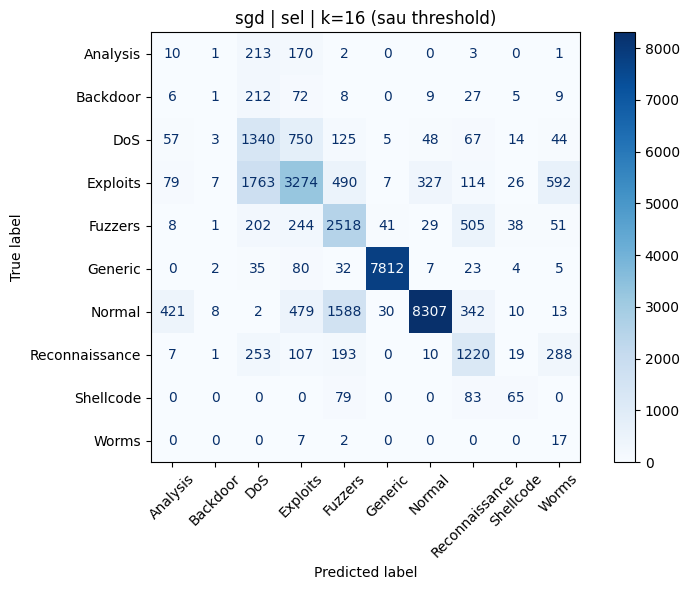

In [38]:
bang_sel_sgd = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k', pp='sel', ma='sgd')
print(bang_sel_sgd.to_string(index=False))
in_ket_qua('sel', 'sgd', bang_sel_sgd, 'So_Dac_Trung_k', best_params)

3.1.8 MLP

In [39]:
class TorchMLP(nn.Module):
  def __init__(self, in_f, out_f, h1=128, h2=64, h3=32, drop=0.2):
    super().__init__()
    self.block1 = nn.Sequential(nn.Linear(in_f, h1), nn.BatchNorm1d(h1), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block2 = nn.Sequential(nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block3 = nn.Sequential(nn.Linear(h2, h3), nn.BatchNorm1d(h3), nn.LeakyReLU(0.1), nn.Dropout(drop / 2))
    self.head = nn.Linear(h3, out_f)
    for m in self.modules():
      if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)
  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    return self.head(x)

In [40]:
param_grid = {'k': K_LIST, 'h1': [128, 256], 'h2': [64, 128], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5521 | đã thử 8/144 tổ hợp


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.6528     0.3570  0.3242    0.3063  0.3064       0.6628 0.8826        4.6125             14.38           7.06
              8    0.7585     0.5815  0.5805    0.5432  0.5411       0.7710 0.9551        7.0093             20.00           7.96
             16    0.7828     0.5959  0.6440    0.5785  0.5695       0.7961 0.9632       12.1926             22.49           7.89
k tốt nhất = 16 | F1 macro: 0.5695 (trước threshold) -> 0.5785 (sau threshold)
Best param: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.33, 'Backdoor': 0.33, 'DoS': 0.0, 'Exploits': 0.0, 'Fuzzers': -0.33, 'Generic': 1.3, 'Normal': 0.0, 'Reconnaissance': -0.98, 'Shellcode': -0.65, 'Worms': -0.33}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    

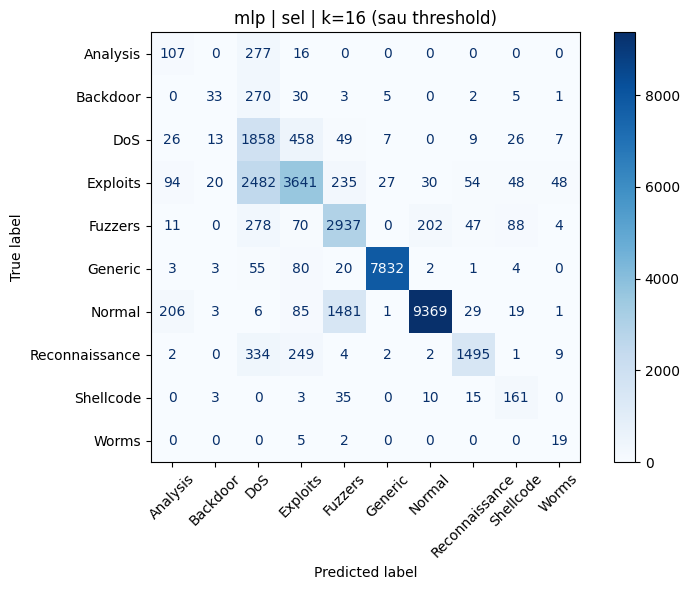

In [41]:
bang_sel_mlp = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k', pp='sel', ma='mlp')
print(bang_sel_mlp.to_string(index=False))
in_ket_qua('sel', 'mlp', bang_sel_mlp, 'So_Dac_Trung_k', best_params)

3.1.9 CNN

In [42]:
class TorchCNN(nn.Module):
  def __init__(self, in_f, out_f, filters=32, ks=3, drop=0.2):
    super().__init__()
    pad = ks // 2
    self.conv1 = nn.Sequential(nn.Conv1d(1, filters, ks, padding=pad), nn.BatchNorm1d(filters), nn.ReLU(), nn.Dropout(drop))
    self.conv2 = nn.Sequential(nn.Conv1d(filters, filters * 2, ks, padding=pad), nn.BatchNorm1d(filters * 2), nn.ReLU(), nn.Dropout(drop))
    self.conv3 = nn.Sequential(nn.Conv1d(filters * 2, filters * 4, ks, padding=pad), nn.BatchNorm1d(filters * 4), nn.ReLU())
    self.avg_pool = nn.AdaptiveAvgPool1d(1)
    self.max_pool = nn.AdaptiveMaxPool1d(1)
    self.classifier = nn.Sequential(nn.Linear(filters * 8, filters * 2), nn.ReLU(), nn.Dropout(drop), nn.Linear(filters * 2, out_f))
  def forward(self, x):
    x = x.unsqueeze(1)
    x = self.conv1(x)
    x = self.conv2(x)
    x = self.conv3(x)
    feat = torch.cat([self.avg_pool(x), self.max_pool(x)], dim=1).squeeze(-1)
    return self.classifier(feat)

In [43]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=6)

Best params: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5605 | đã thử 6/144 tổ hợp


 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
              4    0.5811     0.3338  0.3544    0.2750  0.3060       0.6185 0.8807        5.0100             21.74          40.58
              8    0.7636     0.6813  0.5183    0.5172  0.5328       0.7749 0.9556        9.2368             33.90          40.10
             16    0.7780     0.6292  0.6348    0.5964  0.5796       0.7927 0.9639       20.6224             50.45          72.25
k tốt nhất = 16 | F1 macro: 0.5796 (trước threshold) -> 0.5964 (sau threshold)
Best param: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.0, 'Backdoor': 0.33, 'DoS': 0.0, 'Exploits': 0.0, 'Fuzzers': 0.99, 'Generic': -1.98, 'Normal': 0.0, 'Reconnaissance': -0.66, 'Shellcode': 0.0, 'Worms': -1.32}
>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
   

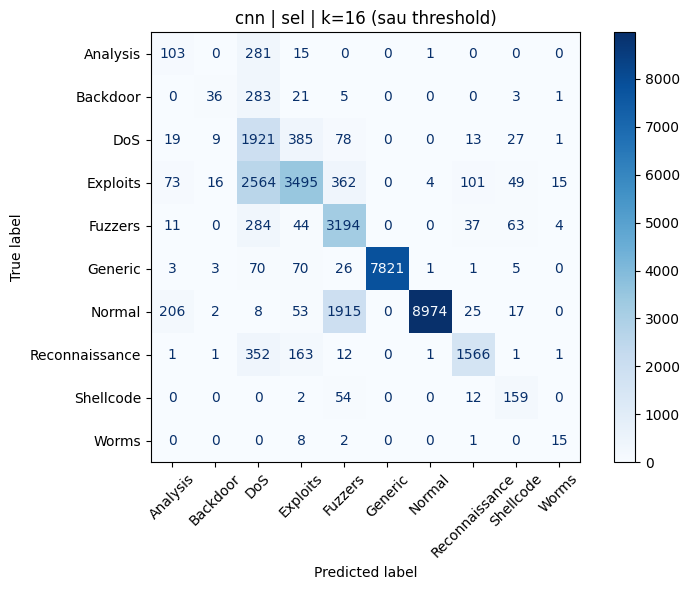

In [44]:
bang_sel_cnn = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k', pp='sel', ma='cnn')
print(bang_sel_cnn.to_string(index=False))
in_ket_qua('sel', 'cnn', bang_sel_cnn, 'So_Dac_Trung_k', best_params)

3.1.10 Tabnet

In [45]:
def build_tabnet(n_d, n_steps, gamma, lr):
  return TabNetClassifier(
      n_d=n_d,
      n_a=n_d,
      n_steps=n_steps,
      gamma=gamma,
      n_independent=2,
      n_shared=2,
      momentum=0.02,
      clip_value=2.0,
      lambda_sparse=1e-4,
      optimizer_fn=torch.optim.Adam,
      optimizer_params=dict(lr=lr, weight_decay=1e-5),
      scheduler_fn=torch.optim.lr_scheduler.StepLR,
      scheduler_params=dict(step_size=10, gamma=0.9),
      mask_type='entmax',
      seed=42,
      verbose=0
  )

In [46]:
param_grid = {'k': K_LIST, 'n_d': [8, 16, 32], 'n_steps': [3, 4], 'gamma': [1.3, 1.5], 'lr': [1e-2, 2e-2], 'cw': [0, 1]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=5)


Early stopping occurred at epoch 27 with best_epoch = 19 and best_val_logloss = 0.66037

Early stopping occurred at epoch 49 with best_epoch = 41 and best_val_logloss = 0.64191

Early stopping occurred at epoch 36 with best_epoch = 28 and best_val_logloss = 0.64667

Early stopping occurred at epoch 21 with best_epoch = 13 and best_val_logloss = 1.13114

Early stopping occurred at epoch 24 with best_epoch = 16 and best_val_logloss = 1.11592

Early stopping occurred at epoch 19 with best_epoch = 11 and best_val_logloss = 1.14296

Early stopping occurred at epoch 50 with best_epoch = 42 and best_val_logloss = 0.53428

Early stopping occurred at epoch 39 with best_epoch = 31 and best_val_logloss = 0.53604
Stop training because you reached max_epochs = 60 with best_epoch = 54 and best_val_logloss = 0.52674

Early stopping occurred at epoch 52 with best_epoch = 44 and best_val_logloss = 0.66852

Early stopping occurred at epoch 38 with best_epoch = 30 and best_val_logloss = 0.67813

Early s


Early stopping occurred at epoch 43 with best_epoch = 35 and best_val_logloss = 1.13962

Early stopping occurred at epoch 30 with best_epoch = 22 and best_val_logloss = 1.13484

Early stopping occurred at epoch 24 with best_epoch = 16 and best_val_logloss = 1.13727

Early stopping occurred at epoch 25 with best_epoch = 17 and best_val_logloss = 1.13301

Early stopping occurred at epoch 37 with best_epoch = 29 and best_val_logloss = 0.74528

Early stopping occurred at epoch 43 with best_epoch = 35 and best_val_logloss = 0.75171

Early stopping occurred at epoch 48 with best_epoch = 40 and best_val_logloss = 0.7503
Stop training because you reached max_epochs = 60 with best_epoch = 52 and best_val_logloss = 0.70938

Early stopping occurred at epoch 52 with best_epoch = 44 and best_val_logloss = 0.66852

Early stopping occurred at epoch 38 with best_epoch = 30 and best_val_logloss = 0.67813

Early stopping occurred at epoch 33 with best_epoch = 25 and best_val_logloss = 0.68147

Early st

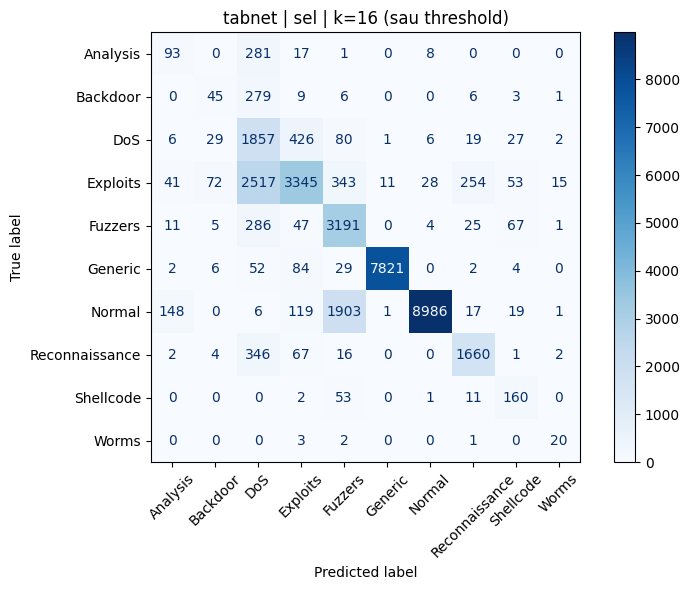

In [47]:
bang_sel_tabnet = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k', pp='sel', ma='tabnet')
print(bang_sel_tabnet.to_string(index=False))
in_ket_qua('sel', 'tabnet', bang_sel_tabnet, 'So_Dac_Trung_k', best_params)

# 3.2 Feature extraction (PCA)

In [48]:
def khong_gian_pca(k, X_a, y_a, X_b):
  pca = PCA(n_components=k, random_state=42).fit(X_a)
  return pca.transform(X_a), pca.transform(X_b)

3.2.1 Logistic Regression

In [49]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', LogisticRegression(max_iter=2000, tol=1e-3, random_state=42)),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__C': [0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced'],
}]
grid_log_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_log_pca.fit(x_train, y_train)
print('Best params:', grid_log_pca.best_params_, '| CV F1 macro:', round(grid_log_pca.best_score_, 4))

Best params: {'pca__n_components': 16, 'model__class_weight': None, 'model__C': 1} | CV F1 macro: 0.3825


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.6111     0.3699  0.3731    0.3467  0.2571       0.6412 0.8588        6.7472              9.27          50.18
                 8    0.6610     0.4094  0.4434    0.4011  0.2988       0.6804 0.8980        9.6580              9.81          34.88
                16    0.7198     0.4847  0.4879    0.4662  0.3808       0.7330 0.9274       11.8678             10.22          35.39
k tốt nhất = 16 | F1 macro: 0.3808 (trước threshold) -> 0.4662 (sau threshold)
Best param: {'pca__n_components': 16, 'model__class_weight': None, 'model__C': 1}
Threshold (bias) theo lớp: {'Analysis': 1.27, 'Backdoor': 1.9, 'DoS': 0.32, 'Exploits': 0.0, 'Fuzzers': 0.32, 'Generic': -2.85, 'Normal': -0.63, 'Reconnaissance': 0.32, 'Shellcode': 2.22, 'Worms': 2.22}


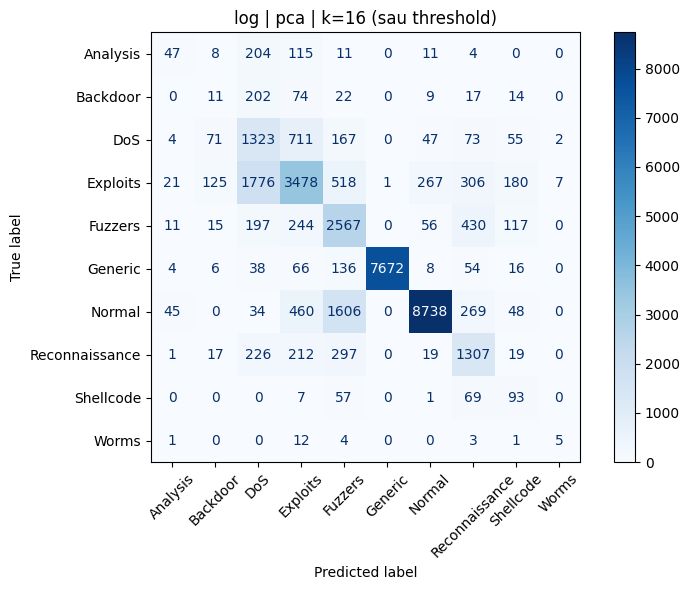

In [50]:
bang_pca_log = bang_sklearn(grid_log_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, pp='pca', ma='log', n_jobs=-1)
print(bang_pca_log.to_string(index=False))
in_ket_qua('pca', 'log', bang_pca_log, 'So_Thanh_Phan_PCA', grid_log_pca.best_params_)

3.2.2 Bayes

In [51]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', GaussianNB()),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3],
}]
grid_nb_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_nb_pca.fit(x_train, y_train)
print('Best params:', grid_nb_pca.best_params_, '| CV F1 macro:', round(grid_nb_pca.best_score_, 4))

Best params: {'pca__n_components': 16, 'model__var_smoothing': 0.0001} | CV F1 macro: 0.3553


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.6146     0.3304  0.3376    0.3182  0.2972       0.6356 0.8409        0.1483              7.54          43.66
                 8    0.6269     0.3653  0.3621    0.3480  0.3251       0.6502 0.8724        0.1644              7.39          49.31
                16    0.6754     0.4223  0.4322    0.4124  0.3558       0.6922 0.8855        0.1836              7.57          61.02
k tốt nhất = 16 | F1 macro: 0.3558 (trước threshold) -> 0.4124 (sau threshold)
Best param: {'pca__n_components': 16, 'model__var_smoothing': 0.0001}
Threshold (bias) theo lớp: {'Analysis': -0.66, 'Backdoor': 0.99, 'DoS': 0.0, 'Exploits': 0.66, 'Fuzzers': 1.32, 'Generic': 0.0, 'Normal': -1.65, 'Reconnaissance': 1.32, 'Shellcode': 0.99, 'Worms': -4.95}


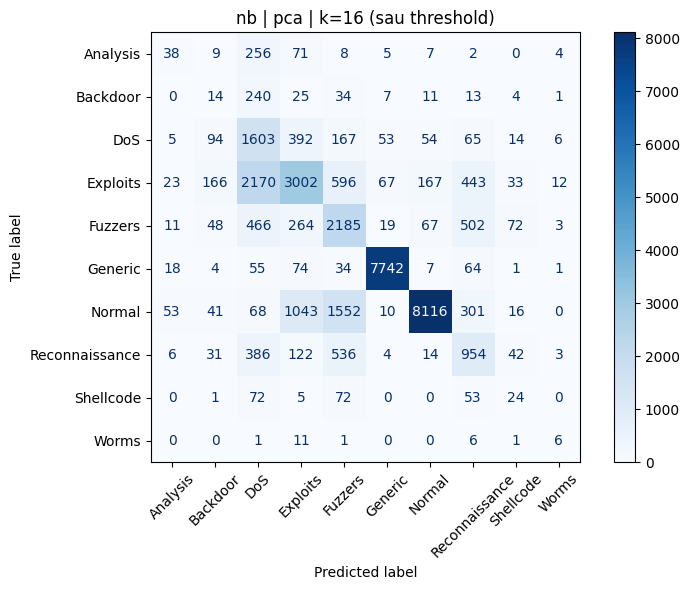

In [52]:
bang_pca_nb = bang_sklearn(grid_nb_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, pp='pca', ma='nb', n_jobs=-1)
print(bang_pca_nb.to_string(index=False))
in_ket_qua('pca', 'nb', bang_pca_nb, 'So_Thanh_Phan_PCA', grid_nb_pca.best_params_)

3.2.3 KNN

In [53]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__n_neighbors': [3, 5, 9, 15, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}]
grid_knn_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(12), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_knn_pca.fit(x_train, y_train)
print('Best params:', grid_knn_pca.best_params_, '| CV F1 macro:', round(grid_knn_pca.best_score_, 4))

Best params: {'pca__n_components': 8, 'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 5} | CV F1 macro: 0.5031


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.7451     0.4958  0.4899    0.4786  0.4553       0.7574 0.7974        0.2558              7.54         314.30
                 8    0.7630     0.5468  0.5215    0.5153  0.5115       0.7763 0.8259        0.3607              8.26         898.72
                16    0.7661     0.5696  0.5385    0.5350  0.5140       0.7780 0.8254        0.1142             81.67       22803.20
k tốt nhất = 16 | F1 macro: 0.514 (trước threshold) -> 0.535 (sau threshold)
Best param: {'pca__n_components': 8, 'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 5}
Threshold (bias) theo lớp: {'Analysis': 0.63, 'Backdoor': 0.63, 'DoS': 0.95, 'Exploits': -0.32, 'Fuzzers': 0.32, 'Generic': -4.76, 'Normal': -0.95, 'Reconnaissance': 0.0, 'Shellcode': 0.32, 'Worms': 0.32}


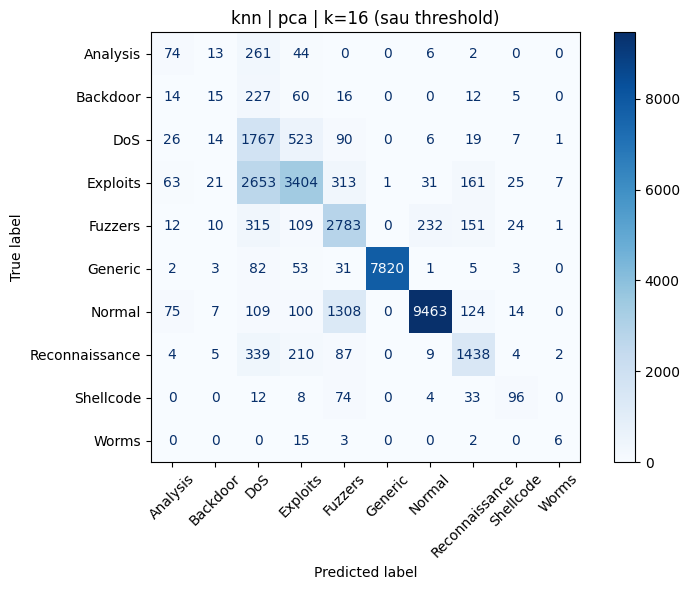

In [54]:
bang_pca_knn = bang_sklearn(grid_knn_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, pp='pca', ma='knn', n_jobs=-1)
print(bang_pca_knn.to_string(index=False))
in_ket_qua('pca', 'knn', bang_pca_knn, 'So_Thanh_Phan_PCA', grid_knn_pca.best_params_)

3.2.4 SVM

In [55]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', SVC(kernel='rbf', cache_size=2000, decision_function_shape='ovr', random_state=42)),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__C': [1, 5, 20],
    'model__gamma': ['scale', 0.02, 0.1],
    'model__class_weight': [None, 'balanced'],
}]
grid_svm_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(8), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_svm_pca.fit(x_svm, y_svm)
print('Best params:', grid_svm_pca.best_params_, '| CV F1 macro:', round(grid_svm_pca.best_score_, 4))

Best params: {'pca__n_components': 16, 'model__gamma': 0.1, 'model__class_weight': None, 'model__C': 20} | CV F1 macro: 0.5874


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.6988     0.4467  0.4586    0.4319  0.4184       0.7213 0.8658       44.3402             31.77       37779.25
                 8    0.7571     0.5543  0.6046    0.5372  0.5416       0.7693 0.9253       34.9829             26.88       33177.54
                16    0.7511     0.5274  0.6211    0.5333  0.5565       0.7695 0.9330       49.9073             33.70       36263.74
k tốt nhất = 8 | F1 macro: 0.5416 (trước threshold) -> 0.5372 (sau threshold)
Best param: {'pca__n_components': 16, 'model__gamma': 0.1, 'model__class_weight': None, 'model__C': 20}
Threshold (bias) theo lớp: {'Analysis': -0.62, 'Backdoor': -0.62, 'DoS': -1.86, 'Exploits': -1.55, 'Fuzzers': -0.93, 'Generic': -0.93, 'Normal': -0.93, 'Reconnaissance': -0.93, 'Shellcode': -0.93, 'Worms': 0.0}


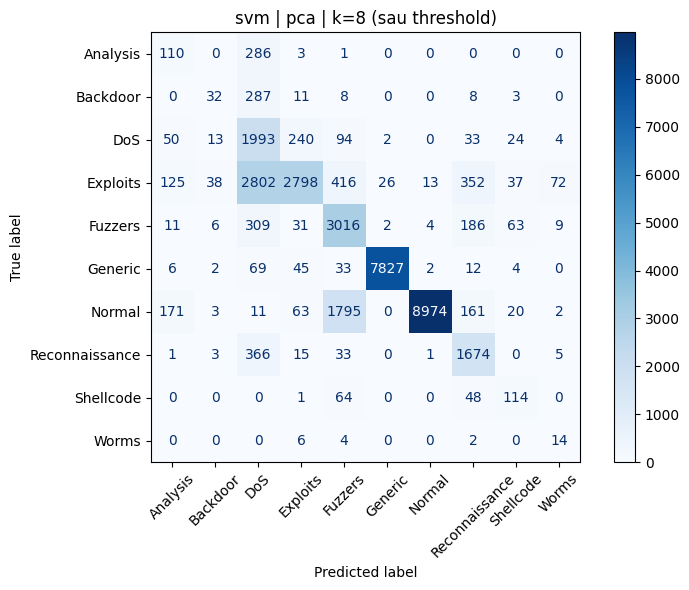

In [56]:
bang_pca_svm = bang_sklearn(grid_svm_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_svm, x_test, y_tr=y_svm, pp='pca', ma='svm', n_jobs=-1)
print(bang_pca_svm.to_string(index=False))
in_ket_qua('pca', 'svm', bang_pca_svm, 'So_Thanh_Phan_PCA', grid_svm_pca.best_params_)

3.2.5 DecisionTree

In [57]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42)),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [8, 12, 16, 20, 30, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__class_weight': [None, 'balanced'],
}]
grid_dt_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(30), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_dt_pca.fit(x_train, y_train)
print('Best params:', grid_dt_pca.best_params_, '| CV F1 macro:', round(grid_dt_pca.best_score_, 4))

Best params: {'pca__n_components': 16, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 16, 'model__criterion': 'entropy', 'model__class_weight': None} | CV F1 macro: 0.5008


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.7384     0.4951  0.4957    0.4734  0.4310       0.7510 0.8688        1.5629              7.95          16.62
                 8    0.7620     0.5552  0.5551    0.5260  0.4910       0.7734 0.8821        2.8503              8.91          16.09
                16    0.7665     0.5518  0.5473    0.5263  0.4993       0.7770 0.8724        5.5577             10.71          17.71
k tốt nhất = 16 | F1 macro: 0.4993 (trước threshold) -> 0.5263 (sau threshold)
Best param: {'pca__n_components': 16, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 16, 'model__criterion': 'entropy', 'model__class_weight': None}
Threshold (bias) theo lớp: {'Analysis': 0.99, 'Backdoor': 0.66, 'DoS': 0.33, 'Exploits': -0.33, 'Fuzzers': 0.33, 'Generic': -4.94, 'Normal': -0.66, 'Reconnaissance': 0.66, 'Shellcode': 0.66, 'Worms': 0.99}


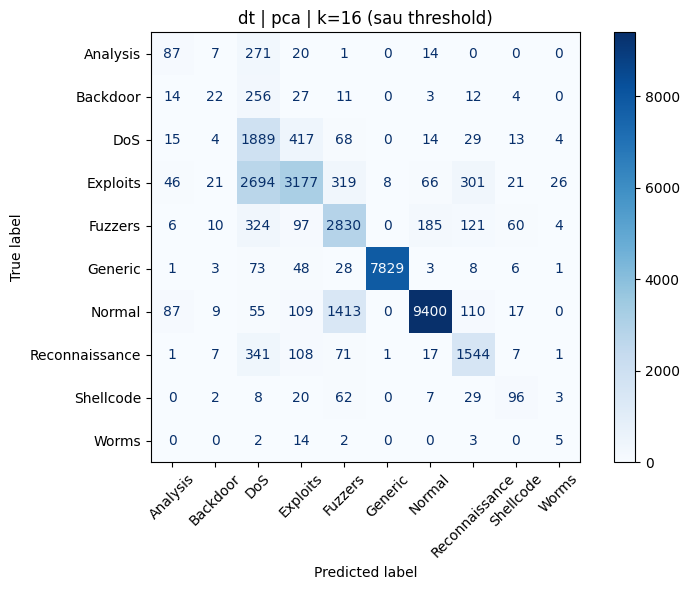

In [58]:
bang_pca_dt = bang_sklearn(grid_dt_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, pp='pca', ma='dt', n_jobs=-1)
print(bang_pca_dt.to_string(index=False))
in_ket_qua('pca', 'dt', bang_pca_dt, 'So_Thanh_Phan_PCA', grid_dt_pca.best_params_)

3.2.6 XGB

In [59]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', XGBClassifier(tree_method='hist', eval_metric='mlogloss', device='cuda' if USE_GPU else 'cpu', random_state=42)),
])
param_grid = [{
    'pca__n_components': K_LIST,
    'model__n_estimators': [200, 400, 600],
    'model__max_depth': [4, 6, 8, 10],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5],
    'model__reg_lambda': [1, 5, 10],
}]
grid_xgb_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(15), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=NJ_XGB)
grid_xgb_pca.fit(x_train, y_train)
print('Best params:', grid_xgb_pca.best_params_, '| CV F1 macro:', round(grid_xgb_pca.best_score_, 4))

Best params: {'pca__n_components': 16, 'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.8} | CV F1 macro: 0.525


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.7542     0.5274  0.5071    0.4958  0.4572       0.7660 0.9388        9.1212             32.07         184.09
                 8    0.7829     0.6140  0.5832    0.5612  0.5209       0.7925 0.9488       11.1102             36.25         191.07
                16    0.7868     0.6697  0.5876    0.5791  0.5327       0.7973 0.9491       13.3982             43.60         205.45
k tốt nhất = 16 | F1 macro: 0.5327 (trước threshold) -> 0.5791 (sau threshold)
Best param: {'pca__n_components': 16, 'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.8}
Threshold (bias) theo lớp: {'Analysis': 0.0, 'Backdoor': 0.97, 'DoS': 0.97, 'Exploits': -0.32, 'Fuzzers': -0.65, 'Generic': -2.58, 'Normal': -1.62, 'Reconnaissa

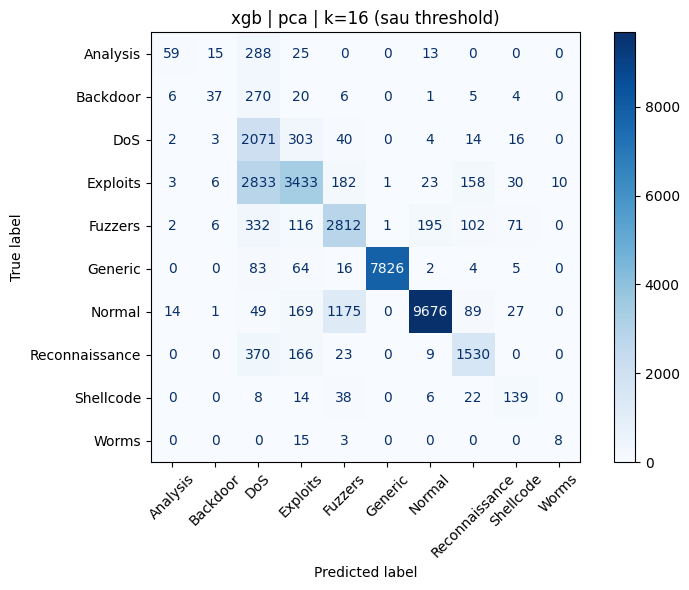

In [60]:
bang_pca_xgb = bang_sklearn(grid_xgb_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, pp='pca', ma='xgb', n_jobs=NJ_XGB)
print(bang_pca_xgb.to_string(index=False))
in_ket_qua('pca', 'xgb', bang_pca_xgb, 'So_Thanh_Phan_PCA', grid_xgb_pca.best_params_)

3.2.7 SGD

In [61]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 5e-3, 2e-3], 'weight_decay': [1e-4, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'lr': 0.002, 'weight_decay': 0.0001, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.3952 | đã thử 8/54 tổ hợp


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.6357     0.3136  0.3322    0.3151  0.2892       0.6462 0.8134        1.8899             11.51           5.36
                 8    0.6124     0.3928  0.3802    0.3620  0.3151       0.6517 0.8824        7.4361             21.31           6.04
                16    0.6941     0.4389  0.5041    0.4236  0.3981       0.7117 0.9157        7.9598             22.81           7.44
k tốt nhất = 16 | F1 macro: 0.3981 (trước threshold) -> 0.4236 (sau threshold)
Best param: {'k': 16, 'lr': 0.002, 'weight_decay': 0.0001, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.49, 'Backdoor': 0.74, 'DoS': 0.0, 'Exploits': -0.25, 'Fuzzers': 0.25, 'Generic': 0.49, 'Normal': -0.49, 'Reconnaissance': 0.25, 'Shellcode': 1.23, 'Worms': 1.23}


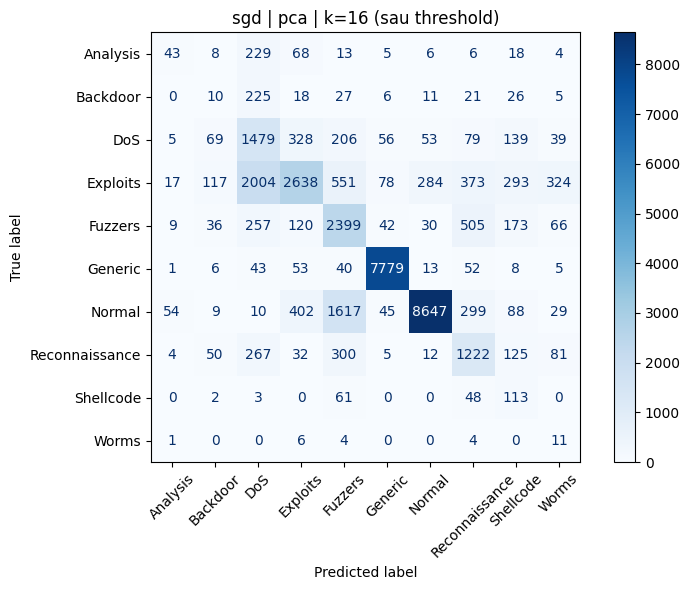

In [62]:
bang_pca_sgd = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA', pp='pca', ma='sgd')
print(bang_pca_sgd.to_string(index=False))
in_ket_qua('pca', 'sgd', bang_pca_sgd, 'So_Thanh_Phan_PCA', best_params)

3.2.8 MLP

In [63]:
param_grid = {'k': K_LIST, 'h1': [128, 256], 'h2': [64, 128], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5470 | đã thử 8/144 tổ hợp


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.7432     0.4822  0.4859    0.4704  0.4655       0.7569 0.9433       11.3316             29.79           7.23
                 8    0.7664     0.5757  0.5895    0.5440  0.5360       0.7788 0.9586       11.1785             24.94           7.77
                16    0.7724     0.5687  0.6176    0.5654  0.5525       0.7839 0.9617        8.8187             24.84           8.78
k tốt nhất = 16 | F1 macro: 0.5525 (trước threshold) -> 0.5654 (sau threshold)
Best param: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.0, 'Backdoor': 0.65, 'DoS': 0.33, 'Exploits': 0.33, 'Fuzzers': 0.0, 'Generic': 2.62, 'Normal': 0.0, 'Reconnaissance': -0.33, 'Shellcode': -0.33, 'Worms': 0.0}


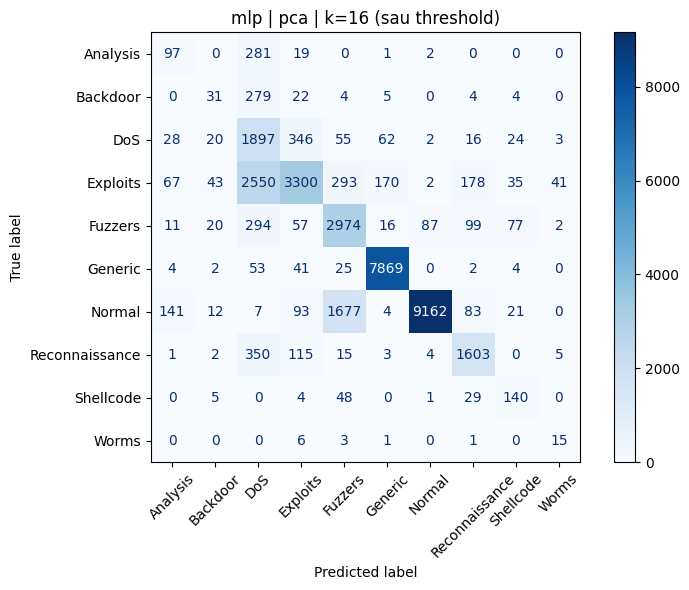

In [64]:
bang_pca_mlp = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA', pp='pca', ma='mlp')
print(bang_pca_mlp.to_string(index=False))
in_ket_qua('pca', 'mlp', bang_pca_mlp, 'So_Thanh_Phan_PCA', best_params)

3.2.9 CNN

In [65]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=6)

Best params: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5314 | đã thử 6/144 tổ hợp


 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
                 4    0.7315     0.4968  0.4913    0.4661  0.4563       0.7487 0.9414        9.9509             26.25          42.79
                 8    0.7685     0.5383  0.5838    0.5387  0.5300       0.7813 0.9580       12.9893             33.02          40.61
                16    0.7721     0.5450  0.5912    0.5508  0.5343       0.7857 0.9598       23.1014             53.12          72.80
k tốt nhất = 16 | F1 macro: 0.5343 (trước threshold) -> 0.5508 (sau threshold)
Best param: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.33, 'Backdoor': 0.66, 'DoS': 0.0, 'Exploits': 0.0, 'Fuzzers': -0.33, 'Generic': 1.33, 'Normal': 0.0, 'Reconnaissance': -0.66, 'Shellcode': -1.0, 'Worms': -0.66}


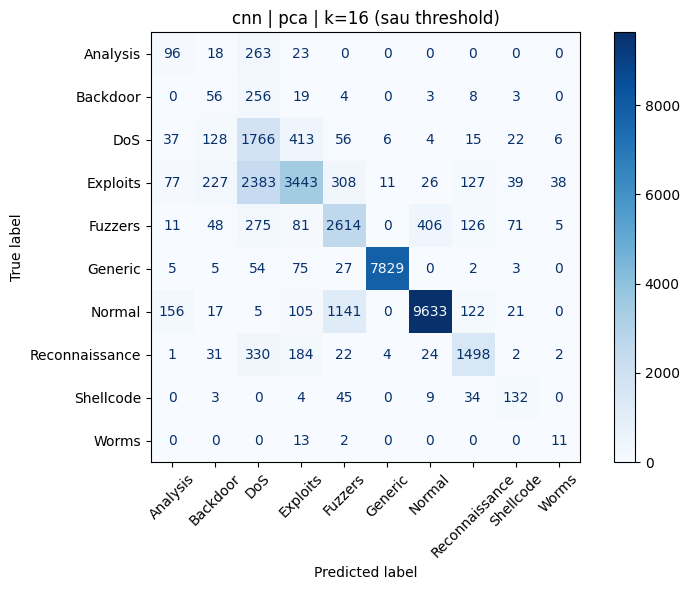

In [66]:
bang_pca_cnn = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA', pp='pca', ma='cnn')
print(bang_pca_cnn.to_string(index=False))
in_ket_qua('pca', 'cnn', bang_pca_cnn, 'So_Thanh_Phan_PCA', best_params)

3.2.10 Tabnet

In [67]:
param_grid = {'k': K_LIST, 'n_d': [8, 16, 32], 'n_steps': [3, 4], 'gamma': [1.3, 1.5], 'lr': [1e-2, 2e-2], 'cw': [0, 1]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=5)


Early stopping occurred at epoch 41 with best_epoch = 33 and best_val_logloss = 0.69593

Early stopping occurred at epoch 49 with best_epoch = 41 and best_val_logloss = 0.67336

Early stopping occurred at epoch 35 with best_epoch = 27 and best_val_logloss = 0.69797

Early stopping occurred at epoch 31 with best_epoch = 23 and best_val_logloss = 0.84945

Early stopping occurred at epoch 49 with best_epoch = 41 and best_val_logloss = 0.80318

Early stopping occurred at epoch 47 with best_epoch = 39 and best_val_logloss = 0.81977
Stop training because you reached max_epochs = 60 with best_epoch = 53 and best_val_logloss = 0.49605

Early stopping occurred at epoch 54 with best_epoch = 46 and best_val_logloss = 0.50966
Stop training because you reached max_epochs = 60 with best_epoch = 57 and best_val_logloss = 0.50574

Early stopping occurred at epoch 36 with best_epoch = 28 and best_val_logloss = 0.73734

Early stopping occurred at epoch 56 with best_epoch = 48 and best_val_logloss = 0.7


Early stopping occurred at epoch 27 with best_epoch = 19 and best_val_logloss = 0.85403

Early stopping occurred at epoch 30 with best_epoch = 22 and best_val_logloss = 0.8677

Early stopping occurred at epoch 44 with best_epoch = 36 and best_val_logloss = 0.84286

Early stopping occurred at epoch 39 with best_epoch = 31 and best_val_logloss = 0.82976

Early stopping occurred at epoch 31 with best_epoch = 23 and best_val_logloss = 0.74463

Early stopping occurred at epoch 47 with best_epoch = 39 and best_val_logloss = 0.70585

Early stopping occurred at epoch 47 with best_epoch = 39 and best_val_logloss = 0.72645

Early stopping occurred at epoch 37 with best_epoch = 29 and best_val_logloss = 0.71324

Early stopping occurred at epoch 41 with best_epoch = 33 and best_val_logloss = 0.69593

Early stopping occurred at epoch 49 with best_epoch = 41 and best_val_logloss = 0.67336

Early stopping occurred at epoch 35 with best_epoch = 27 and best_val_logloss = 0.69797

Early stopping occurr

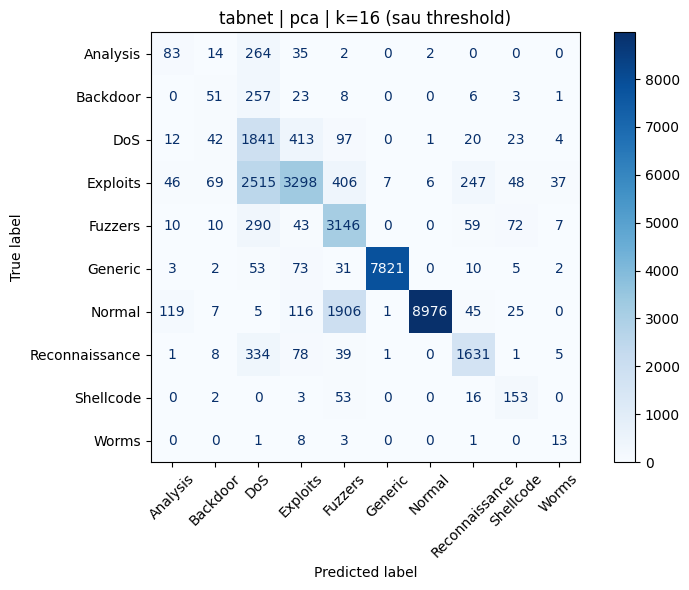

In [68]:
bang_pca_tabnet = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA', pp='pca', ma='tabnet')
print(bang_pca_tabnet.to_string(index=False))
in_ket_qua('pca', 'tabnet', bang_pca_tabnet, 'So_Thanh_Phan_PCA', best_params)

# 3.3 Feature extraction (Autoencoder)

Autoencoder học nén dữ liệu về không gian ẩn k chiều (k thuộc `K_LIST`), không dùng nhãn. Sau đó 10 mô hình được huấn luyện và tuning trên không gian ẩn này.

3.3.0 Tạo và huấn luyện Autoencoder

In [69]:
class AutoEncoder(nn.Module):
  def __init__(self, in_f, latent, h1=128, h2=64):
    super().__init__()
    self.encoder = nn.Sequential(
        nn.Linear(in_f, h1), nn.LeakyReLU(0.1),
        nn.Linear(h1, h2), nn.LeakyReLU(0.1),
        nn.Linear(h2, latent))
    self.decoder = nn.Sequential(
        nn.Linear(latent, h2), nn.LeakyReLU(0.1),
        nn.Linear(h2, h1), nn.LeakyReLU(0.1),
        nn.Linear(h1, in_f))
  def forward(self, x):
    z = self.encoder(x)
    return self.decoder(z)

In [70]:
torch.manual_seed(42)
np.random.seed(42)


def train_autoencoder(x_tr, latent, epochs=AE_EPOCHS, lr=1e-3, patience=10, val_size=0.1):
  x_a, x_v = train_test_split(x_tr, test_size=val_size, random_state=42)
  net = AutoEncoder(x_tr.shape[1], latent).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
  loader = GPULoader(to_t(x_a).to(device), bs=512)
  xv = to_t(x_v).to(device)

  def step_loss(net, batch):
    bx = batch[0]
    return nn.functional.mse_loss(net(bx), bx)

  def val_mse(net):
    return nn.functional.mse_loss(net(xv), xv).item()

  net, best = train_es(net, opt, loader, step_loss, val_mse, epochs, patience, 'min')
  print(f'  latent = {latent} | best val MSE: {best:.4f}')
  return net


def encode(net, x):
  net.eval()
  with torch.no_grad():
    return net.encoder(to_t(x).to(device)).cpu().numpy()


def recon_mse(net, x):
  net.eval()
  with torch.no_grad():
    xt = to_t(x).to(device)
    return nn.functional.mse_loss(net(xt), xt).item()

In [71]:
z_train_parts, z_test_parts, rows = [], [], []

for k in K_LIST:
  print(f'Train Autoencoder, latent = {k}')
  t0 = time.time()
  ae = train_autoencoder(np.asarray(x_train), k)
  train_time = time.time() - t0

  z_train_parts.append(encode(ae, np.asarray(x_train)))
  z_test_parts.append(encode(ae, np.asarray(x_test)))

  rows.append({
      'So_Chieu_AE': k,
      'Recon_MSE_Train': round(recon_mse(ae, np.asarray(x_train)), 4),
      'Recon_MSE_Test': round(recon_mse(ae, np.asarray(x_test)), 4),
      'AE_Train_Time_s': round(train_time, 2),
  })

# ghép không gian ẩn của các k thành 1 ma trận: [k=K_LIST[0] | k=K_LIST[1] | ...]
z_train_ae = np.hstack(z_train_parts)
z_test_ae = np.hstack(z_test_parts)

bang_ae_recon = pd.DataFrame(rows)
print(bang_ae_recon.to_string(index=False))
print(z_train_ae.shape, z_test_ae.shape)

Train Autoencoder, latent = 4
  latent = 4 | best val MSE: 0.0052
Train Autoencoder, latent = 8
  latent = 8 | best val MSE: 0.0017
Train Autoencoder, latent = 16
  latent = 16 | best val MSE: 0.0007
 So_Chieu_AE  Recon_MSE_Train  Recon_MSE_Test  AE_Train_Time_s
           4           0.0051          0.0052            46.94
           8           0.0017          0.0017            33.86
          16           0.0007          0.0007            29.33
(140272, 28) (35069, 28)


Hàm chọn đúng không gian ẩn k từ ma trận đã ghép, dùng trong Pipeline qua `FunctionTransformer` (tham số `ae__kw_args`).

In [72]:
def ae_slice(k, ks=tuple(K_LIST)):
  start = sum(v for v in ks if v < k)
  return slice(start, start + k)


def ae_select(X, k):
  return X[:, ae_slice(k)]


def khong_gian_ae(k, X_a, y_a, X_b):
  return X_a[:, ae_slice(k)], X_b[:, ae_slice(k)]

3.3.1 Logistic Regression

In [73]:
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000, tol=1e-3, random_state=42)),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__C': [0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced'],
}]
grid_log_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_log_ae.fit(z_train_ae, y_train)
print('Best params:', grid_log_ae.best_params_, '| CV F1 macro:', round(grid_log_ae.best_score_, 4))

Best params: {'model__class_weight': 'balanced', 'model__C': 10, 'ae__kw_args': {'k': 16}} | CV F1 macro: 0.3755


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.6153     0.3787  0.4012    0.3655  0.2750       0.6448 0.8524        2.7705              8.36          34.48
           8    0.6753     0.3895  0.3936    0.3808  0.3116       0.6912 0.8892        4.2610              8.92          24.49
          16    0.6979     0.4476  0.5153    0.4438  0.3721       0.7140 0.9188        9.5870             10.69          35.17
k tốt nhất = 16 | F1 macro: 0.3721 (trước threshold) -> 0.4438 (sau threshold)
Best param: {'model__class_weight': 'balanced', 'model__C': 10, 'ae__kw_args': {'k': 16}}
Threshold (bias) theo lớp: {'Analysis': -0.91, 'Backdoor': -0.3, 'DoS': 0.0, 'Exploits': 0.6, 'Fuzzers': 0.6, 'Generic': 0.6, 'Normal': 0.0, 'Reconnaissance': 0.0, 'Shellcode': -0.6, 'Worms': -1.81}


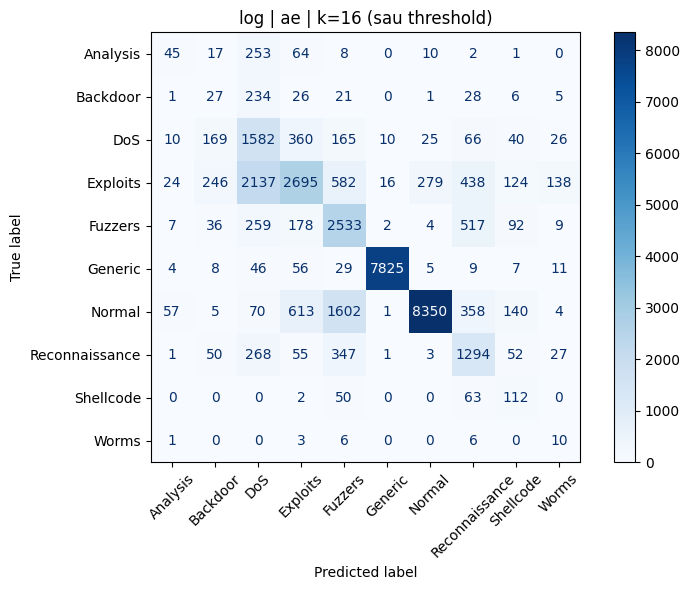

In [74]:
bang_ae_log = bang_sklearn(grid_log_ae, 'ae__kw_args', 'So_Chieu_AE', z_train_ae, z_test_ae, pp='ae', ma='log', k_to_val=lambda k: {'k': k}, n_jobs=-1)
print(bang_ae_log.to_string(index=False))
in_ket_qua('ae', 'log', bang_ae_log, 'So_Chieu_AE', grid_log_ae.best_params_)

3.3.2 Bayes

In [75]:
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', GaussianNB()),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3],
}]
grid_nb_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(10), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_nb_ae.fit(z_train_ae, y_train)
print('Best params:', grid_nb_ae.best_params_, '| CV F1 macro:', round(grid_nb_ae.best_score_, 4))

Best params: {'model__var_smoothing': 1e-08, 'ae__kw_args': {'k': 8}} | CV F1 macro: 0.3223


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.5906     0.3899  0.3659    0.3459  0.2951       0.6132 0.8523        0.0628              7.73          31.58
           8    0.6835     0.4073  0.4030    0.3901  0.3216       0.6994 0.8868        0.0789              7.77          37.56
          16    0.6574     0.4007  0.4018    0.3830  0.3094       0.6708 0.8523        0.1041              7.39          50.76
k tốt nhất = 8 | F1 macro: 0.3216 (trước threshold) -> 0.3901 (sau threshold)
Best param: {'model__var_smoothing': 1e-08, 'ae__kw_args': {'k': 8}}
Threshold (bias) theo lớp: {'Analysis': 2.0, 'Backdoor': 1.0, 'DoS': 0.0, 'Exploits': 0.67, 'Fuzzers': 0.0, 'Generic': 4.67, 'Normal': -1.0, 'Reconnaissance': 1.34, 'Shellcode': 2.0, 'Worms': 0.67}


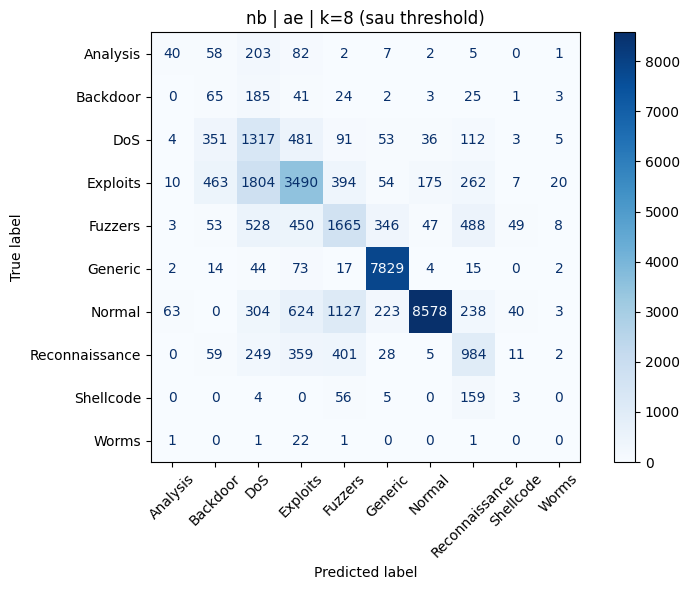

In [76]:
bang_ae_nb = bang_sklearn(grid_nb_ae, 'ae__kw_args', 'So_Chieu_AE', z_train_ae, z_test_ae, pp='ae', ma='nb', k_to_val=lambda k: {'k': k}, n_jobs=-1)
print(bang_ae_nb.to_string(index=False))
in_ket_qua('ae', 'nb', bang_ae_nb, 'So_Chieu_AE', grid_nb_ae.best_params_)

3.3.3 KNN

In [77]:
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__n_neighbors': [3, 5, 9, 15, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}]
grid_knn_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(12), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_knn_ae.fit(z_train_ae, y_train)
print('Best params:', grid_knn_ae.best_params_, '| CV F1 macro:', round(grid_knn_ae.best_score_, 4))

Best params: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 5, 'ae__kw_args': {'k': 16}} | CV F1 macro: 0.5072


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7551     0.5561  0.4937    0.4949  0.4796       0.7662 0.7968        0.1632              7.29         282.23
           8    0.7744     0.5760  0.5364    0.5330  0.5105       0.7804 0.8225        0.2526              8.99        1497.43
          16    0.7724     0.6108  0.5361    0.5318  0.5117       0.7790 0.8194        0.0581            123.75       31963.00
k tốt nhất = 8 | F1 macro: 0.5105 (trước threshold) -> 0.533 (sau threshold)
Best param: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 5, 'ae__kw_args': {'k': 16}}
Threshold (bias) theo lớp: {'Analysis': -0.32, 'Backdoor': -0.32, 'DoS': 0.0, 'Exploits': -0.95, 'Fuzzers': 0.0, 'Generic': -0.95, 'Normal': -0.63, 'Reconnaissance': 0.0, 'Shellcode': 0.0, 'Worms': 0.0}


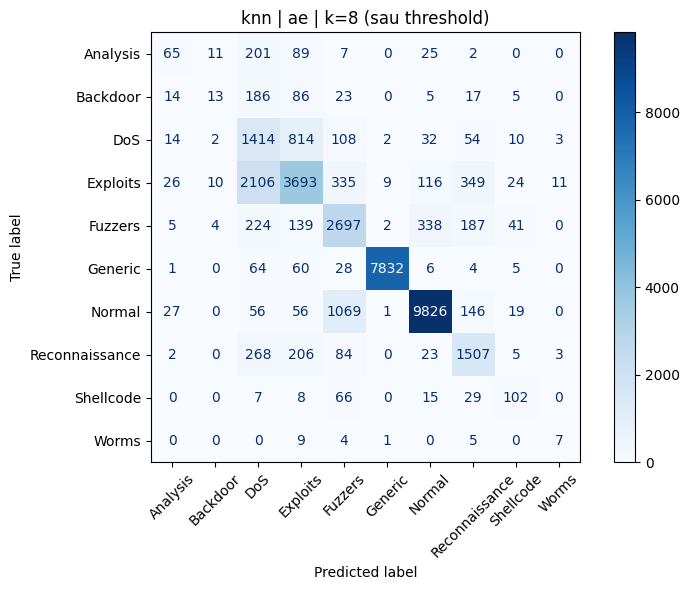

In [78]:
bang_ae_knn = bang_sklearn(grid_knn_ae, 'ae__kw_args', 'So_Chieu_AE', z_train_ae, z_test_ae, pp='ae', ma='knn', k_to_val=lambda k: {'k': k}, n_jobs=-1)
print(bang_ae_knn.to_string(index=False))
in_ket_qua('ae', 'knn', bang_ae_knn, 'So_Chieu_AE', grid_knn_ae.best_params_)

3.3.4 SVM

In [79]:
z_svm = z_train_ae[idx_svm]
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', SVC(kernel='rbf', cache_size=2000, decision_function_shape='ovr', random_state=42)),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__C': [1, 5, 20],
    'model__gamma': ['scale', 0.02, 0.1],
    'model__class_weight': [None, 'balanced'],
}]
grid_svm_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(8), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_svm_ae.fit(z_svm, y_svm)
print('Best params:', grid_svm_ae.best_params_, '| CV F1 macro:', round(grid_svm_ae.best_score_, 4))

Best params: {'model__gamma': 'scale', 'model__class_weight': None, 'model__C': 20, 'ae__kw_args': {'k': 16}} | CV F1 macro: 0.5952


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7196     0.4794  0.5024    0.4626  0.4600       0.7358 0.8963       39.8200             27.28       35149.62
           8    0.7521     0.5345  0.5803    0.5219  0.5137       0.7650 0.9231       36.7903             27.43       35809.35
          16    0.7624     0.5721  0.6215    0.5504  0.5555       0.7745 0.9234       42.2501             29.99       37363.61
k tốt nhất = 16 | F1 macro: 0.5555 (trước threshold) -> 0.5504 (sau threshold)
Best param: {'model__gamma': 'scale', 'model__class_weight': None, 'model__C': 20, 'ae__kw_args': {'k': 16}}
Threshold (bias) theo lớp: {'Analysis': -1.55, 'Backdoor': -0.62, 'DoS': -0.93, 'Exploits': -1.55, 'Fuzzers': -0.93, 'Generic': -1.55, 'Normal': -1.55, 'Reconnaissance': -1.24, 'Shellcode': -1.55, 'Worms': -0.31}


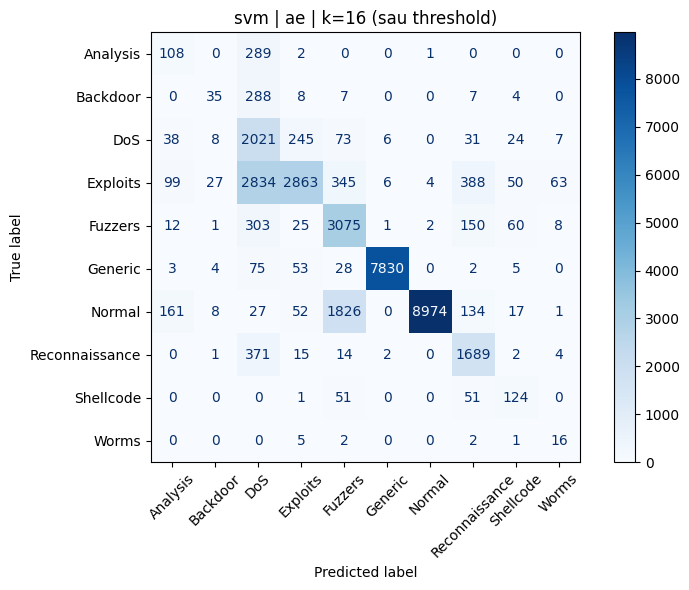

In [80]:
bang_ae_svm = bang_sklearn(grid_svm_ae, 'ae__kw_args', 'So_Chieu_AE', z_svm, z_test_ae, y_tr=y_svm, pp='ae', ma='svm', k_to_val=lambda k: {'k': k}, n_jobs=-1)
print(bang_ae_svm.to_string(index=False))
in_ket_qua('ae', 'svm', bang_ae_svm, 'So_Chieu_AE', grid_svm_ae.best_params_)

3.3.5 DecisionTree

In [81]:
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', DecisionTreeClassifier(random_state=42)),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [8, 12, 16, 20, 30, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__class_weight': [None, 'balanced'],
}]
grid_dt_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(30), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=-1)
grid_dt_ae.fit(z_train_ae, y_train)
print('Best params:', grid_dt_ae.best_params_, '| CV F1 macro:', round(grid_dt_ae.best_score_, 4))

Best params: {'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': None, 'model__criterion': 'entropy', 'model__class_weight': None, 'ae__kw_args': {'k': 16}} | CV F1 macro: 0.4856


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7389     0.5264  0.4982    0.4739  0.4520       0.7469 0.7952        1.5237              7.57          10.18
           8    0.7509     0.5476  0.5123    0.5012  0.4738       0.7605 0.8013        3.0889              8.93          11.20
          16    0.7531     0.5744  0.5175    0.5163  0.4980       0.7596 0.7987        6.4577             10.97          12.05
k tốt nhất = 16 | F1 macro: 0.498 (trước threshold) -> 0.5163 (sau threshold)
Best param: {'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': None, 'model__criterion': 'entropy', 'model__class_weight': None, 'ae__kw_args': {'k': 16}}
Threshold (bias) theo lớp: {'Analysis': 0.64, 'Backdoor': 1.59, 'DoS': 0.95, 'Exploits': -0.32, 'Fuzzers': 0.64, 'Generic': -4.77, 'Normal': 0.0, 'Reconnaissance': 0.64, 'Shellcode': 0.64, 'Worms': 0.0}


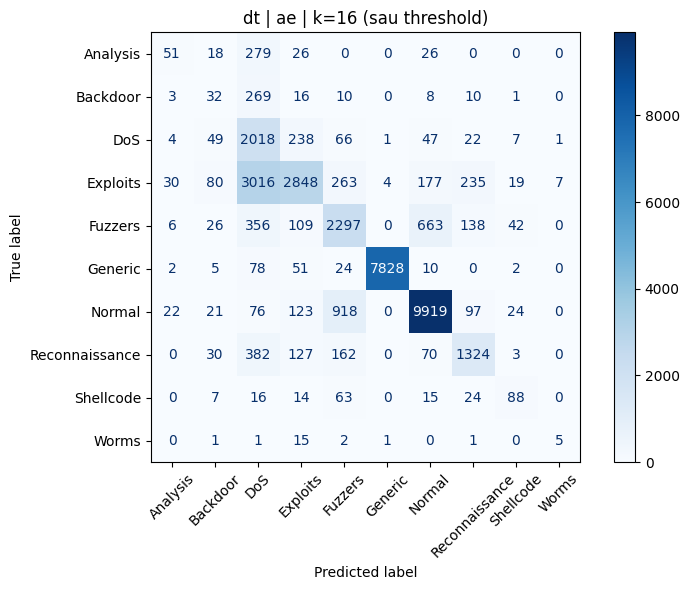

In [82]:
bang_ae_dt = bang_sklearn(grid_dt_ae, 'ae__kw_args', 'So_Chieu_AE', z_train_ae, z_test_ae, pp='ae', ma='dt', k_to_val=lambda k: {'k': k}, n_jobs=-1)
print(bang_ae_dt.to_string(index=False))
in_ket_qua('ae', 'dt', bang_ae_dt, 'So_Chieu_AE', grid_dt_ae.best_params_)

3.3.6 XGB

In [83]:
pipeline = Pipeline([
    ('ae', FunctionTransformer(ae_select, kw_args={'k': K_LIST[0]})),
    ('sc', StandardScaler()),
    ('model', XGBClassifier(tree_method='hist', eval_metric='mlogloss', device='cuda' if USE_GPU else 'cpu', random_state=42)),
])
param_grid = [{
    'ae__kw_args': [{'k': k} for k in K_LIST],
    'model__n_estimators': [200, 400, 600],
    'model__max_depth': [4, 6, 8, 10],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5],
    'model__reg_lambda': [1, 5, 10],
}]
grid_xgb_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=ni(15), cv=st, scoring='f1_macro',
                         random_state=42, n_jobs=NJ_XGB)
grid_xgb_ae.fit(z_train_ae, y_train)
print('Best params:', grid_xgb_ae.best_params_, '| CV F1 macro:', round(grid_xgb_ae.best_score_, 4))

Best params: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 200, 'model__min_child_weight': 5, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0, 'ae__kw_args': {'k': 16}} | CV F1 macro: 0.5134


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7535     0.5373  0.5164    0.4967  0.4545       0.7664 0.9430        4.4504             19.09          77.95
           8    0.7742     0.6042  0.5558    0.5365  0.4877       0.7850 0.9518        5.1646             20.84          81.41
          16    0.7771     0.5920  0.5782    0.5606  0.5243       0.7889 0.9528        6.3047             23.36          84.94
k tốt nhất = 16 | F1 macro: 0.5243 (trước threshold) -> 0.5606 (sau threshold)
Best param: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 200, 'model__min_child_weight': 5, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0, 'ae__kw_args': {'k': 16}}
Threshold (bias) theo lớp: {'Analysis': 1.29, 'Backdoor': 1.62, 'DoS': 0.97, 'Exploits': 0.0, 'Fuzzers': 0.0, 'Generic': -0.32, 'Normal': -0.65, 'Reconnaissance': 0.32, 'Shellcode': 

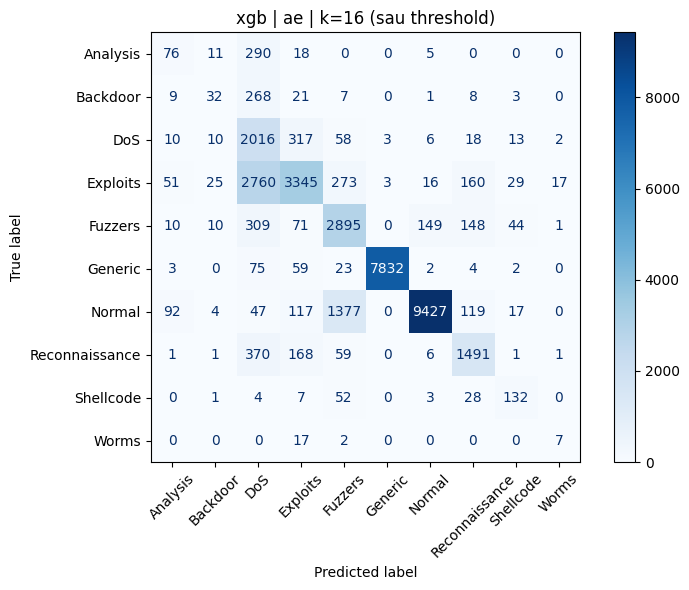

In [84]:
bang_ae_xgb = bang_sklearn(grid_xgb_ae, 'ae__kw_args', 'So_Chieu_AE', z_train_ae, z_test_ae, pp='ae', ma='xgb', k_to_val=lambda k: {'k': k}, n_jobs=NJ_XGB)
print(bang_ae_xgb.to_string(index=False))
in_ket_qua('ae', 'xgb', bang_ae_xgb, 'So_Chieu_AE', grid_xgb_ae.best_params_)

3.3.7 SGD

In [85]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 5e-3, 2e-3], 'weight_decay': [1e-4, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=8)

Best params: {'k': 16, 'lr': 0.005, 'weight_decay': 0.0001, 'cw': 1.0, 'epochs': 60} | OOF F1 macro: 0.3622 | đã thử 8/54 tổ hợp


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.4635     0.3058  0.3358    0.2532  0.2444       0.5179 0.8227        1.5955              7.22           5.83
           8    0.6334     0.3967  0.4249    0.3708  0.3182       0.6633 0.8750        2.4221             11.06           6.08
          16    0.6900     0.4136  0.4352    0.4133  0.3576       0.7044 0.9051        2.4930             14.66           6.40
k tốt nhất = 16 | F1 macro: 0.3576 (trước threshold) -> 0.4133 (sau threshold)
Best param: {'k': 16, 'lr': 0.005, 'weight_decay': 0.0001, 'cw': 1.0, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': -0.24, 'Backdoor': -0.24, 'DoS': 0.0, 'Exploits': 0.47, 'Fuzzers': 0.24, 'Generic': 0.0, 'Normal': -0.24, 'Reconnaissance': 0.24, 'Shellcode': 0.0, 'Worms': -1.41}


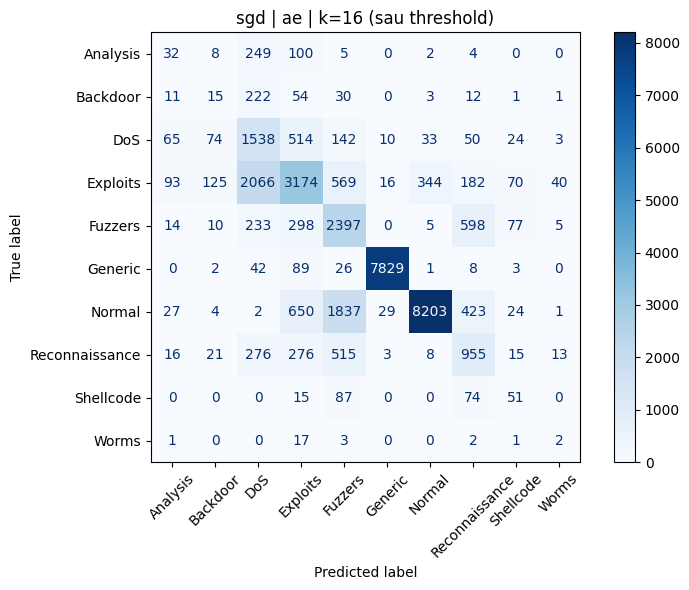

In [86]:
bang_ae_sgd = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE', pp='ae', ma='sgd')
print(bang_ae_sgd.to_string(index=False))
in_ket_qua('ae', 'sgd', bang_ae_sgd, 'So_Chieu_AE', best_params)

3.3.8 MLP

In [87]:
param_grid = {'k': K_LIST, 'h1': [128, 256], 'h2': [64, 128], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=8)

Best params: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5414 | đã thử 8/144 tổ hợp


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7365     0.5142  0.5462    0.4742  0.4714       0.7545 0.9482       10.5983             21.79           7.64
           8    0.7690     0.5312  0.5481    0.5249  0.5195       0.7809 0.9565        9.1891             29.21           7.57
          16    0.7802     0.5631  0.6007    0.5613  0.5430       0.7910 0.9589        8.7962             26.31           8.32
k tốt nhất = 16 | F1 macro: 0.543 (trước threshold) -> 0.5613 (sau threshold)
Best param: {'k': 16, 'h1': 128, 'h2': 64, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': 0.0, 'Backdoor': 0.33, 'DoS': 0.0, 'Exploits': 0.0, 'Fuzzers': 0.33, 'Generic': -1.32, 'Normal': 0.66, 'Reconnaissance': -0.33, 'Shellcode': 0.0, 'Worms': -0.66}


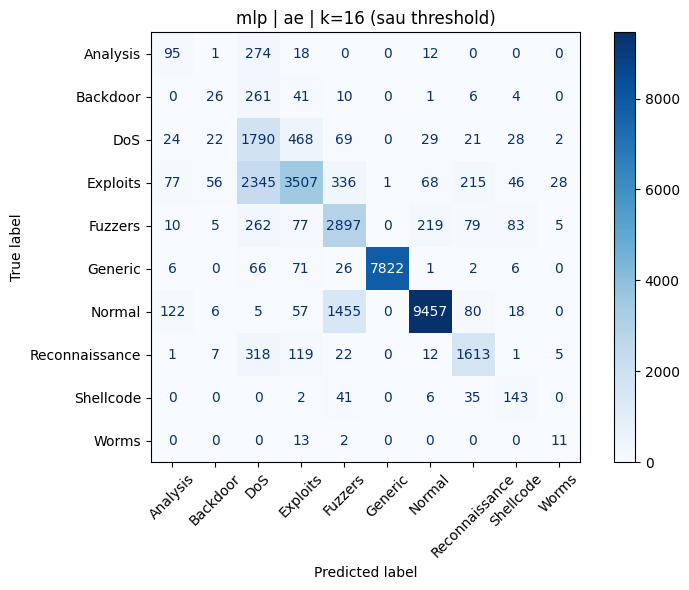

In [88]:
bang_ae_mlp = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE', pp='ae', ma='mlp')
print(bang_ae_mlp.to_string(index=False))
in_ket_qua('ae', 'mlp', bang_ae_mlp, 'So_Chieu_AE', best_params)

3.3.9 CNN

In [89]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.1, 0.25], 'lr': [2e-3, 1e-3], 'cw': [0, 0.5, 1.0], 'epochs': [EPOCHS]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=6)

Best params: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60} | OOF F1 macro: 0.5111 | đã thử 6/144 tổ hợp


 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
           4    0.7475     0.5268  0.5287    0.4984  0.4918       0.7617 0.9510       15.5438             31.66          41.66
           8    0.7652     0.5318  0.5474    0.5245  0.5170       0.7770 0.9565        9.1183             31.46          40.43
          16    0.7635     0.5793  0.5522    0.5394  0.5266       0.7782 0.9568       12.5304             40.98          72.12
k tốt nhất = 16 | F1 macro: 0.5266 (trước threshold) -> 0.5394 (sau threshold)
Best param: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.1, 'lr': 0.002, 'cw': 0.5, 'epochs': 60}
Threshold (bias) theo lớp: {'Analysis': -0.33, 'Backdoor': 0.67, 'DoS': 0.0, 'Exploits': 0.0, 'Fuzzers': 0.0, 'Generic': 1.0, 'Normal': 0.0, 'Reconnaissance': -0.33, 'Shellcode': 0.0, 'Worms': -0.33}


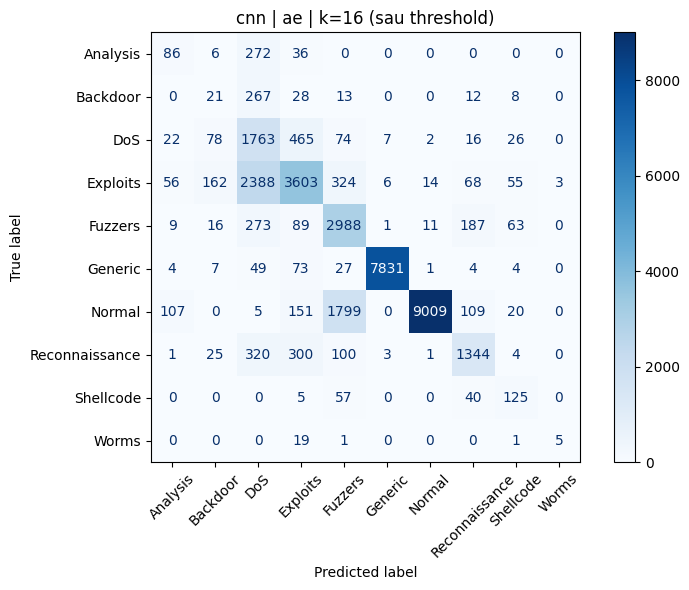

In [90]:
bang_ae_cnn = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE', pp='ae', ma='cnn')
print(bang_ae_cnn.to_string(index=False))
in_ket_qua('ae', 'cnn', bang_ae_cnn, 'So_Chieu_AE', best_params)

3.3.10 Tabnet

In [91]:
param_grid = {'k': K_LIST, 'n_d': [8, 16, 32], 'n_steps': [3, 4], 'gamma': [1.3, 1.5], 'lr': [1e-2, 2e-2], 'cw': [0, 1]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=5)


Early stopping occurred at epoch 38 with best_epoch = 30 and best_val_logloss = 0.6945
Stop training because you reached max_epochs = 60 with best_epoch = 54 and best_val_logloss = 0.66647

Early stopping occurred at epoch 46 with best_epoch = 38 and best_val_logloss = 0.68451

Early stopping occurred at epoch 41 with best_epoch = 33 and best_val_logloss = 0.78965

Early stopping occurred at epoch 37 with best_epoch = 29 and best_val_logloss = 0.78858

Early stopping occurred at epoch 46 with best_epoch = 38 and best_val_logloss = 0.76329

Early stopping occurred at epoch 40 with best_epoch = 32 and best_val_logloss = 0.53027

Early stopping occurred at epoch 50 with best_epoch = 42 and best_val_logloss = 0.53044
Stop training because you reached max_epochs = 60 with best_epoch = 57 and best_val_logloss = 0.5153

Early stopping occurred at epoch 46 with best_epoch = 38 and best_val_logloss = 0.71479

Early stopping occurred at epoch 43 with best_epoch = 35 and best_val_logloss = 0.725


Early stopping occurred at epoch 28 with best_epoch = 20 and best_val_logloss = 0.81524

Early stopping occurred at epoch 37 with best_epoch = 29 and best_val_logloss = 0.81738

Early stopping occurred at epoch 47 with best_epoch = 39 and best_val_logloss = 0.78002

Early stopping occurred at epoch 38 with best_epoch = 30 and best_val_logloss = 0.78845
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_val_logloss = 0.71131

Early stopping occurred at epoch 37 with best_epoch = 29 and best_val_logloss = 0.73623

Early stopping occurred at epoch 39 with best_epoch = 31 and best_val_logloss = 0.71776

Early stopping occurred at epoch 31 with best_epoch = 23 and best_val_logloss = 0.7163

Early stopping occurred at epoch 38 with best_epoch = 30 and best_val_logloss = 0.6945
Stop training because you reached max_epochs = 60 with best_epoch = 54 and best_val_logloss = 0.66647

Early stopping occurred at epoch 46 with best_epoch = 38 and best_val_logloss = 0.684

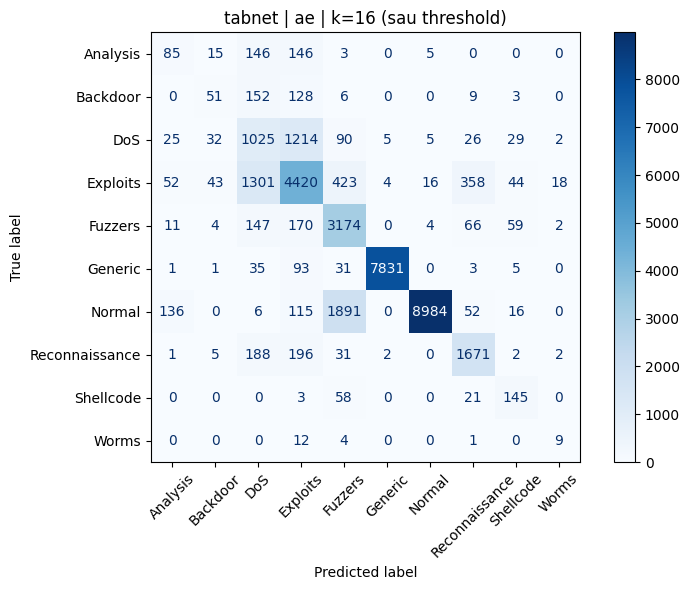

In [92]:
bang_ae_tabnet = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE', pp='ae', ma='tabnet')
print(bang_ae_tabnet.to_string(index=False))
in_ket_qua('ae', 'tabnet', bang_ae_tabnet, 'So_Chieu_AE', best_params)

# Bước 4 : So sánh Feature Selection và Feature Extraction (PCA, Autoencoder)

4.1 Gom kết quả của 10 mô hình

In [93]:
ten_mo_hinh = {
    'Logistic Regression': 'log',
    'Bayes': 'nb',
    'KNN': 'knn',
    'SVM': 'svm',
    'Decision Tree': 'dt',
    'XGBoost': 'xgb',
    'SGD': 'sgd',
    'MLP': 'mlp',
    'CNN': 'cnn',
    'TabNet': 'tabnet',
}

# tên cột "số chiều" của từng phương pháp
phuong_phap = {
    'Selection': ('sel', 'So_Dac_Trung_k'),
    'PCA': ('pca', 'So_Thanh_Phan_PCA'),
    'Autoencoder': ('ae', 'So_Chieu_AE'),
}

frames = []
for pp, (tien_to, cot_k) in phuong_phap.items():
    for ten, ma in ten_mo_hinh.items():
        d = globals()[f'bang_{tien_to}_{ma}'].rename(columns={cot_k: 'k'}).copy()
        d.insert(0, 'Mo_Hinh', ten)
        d.insert(1, 'Phuong_Phap', pp)
        frames.append(d)

all_results = pd.concat(frames, ignore_index=True)
print(all_results.to_string(index=False))

            Mo_Hinh Phuong_Phap  k  Accuracy  Precision  Recall  F1_Score  F1_Goc  F1_Weighted    AUC  Train_Time_s  Threshold_Time_s  Infer_Time_ms
Logistic Regression   Selection  4    0.6281     0.3250  0.3976    0.2992  0.2294       0.6450 0.8668        3.6704              8.05          18.85
Logistic Regression   Selection  8    0.7070     0.4644  0.5364    0.4475  0.3121       0.7199 0.9150        5.3325              8.57          28.48
Logistic Regression   Selection 16    0.7264     0.4845  0.5814    0.4812  0.3893       0.7372 0.9357       12.2315             10.31          21.48
              Bayes   Selection  4    0.5736     0.2944  0.3061    0.2785  0.1379       0.5892 0.8135        0.3512              7.02          24.82
              Bayes   Selection  8    0.6129     0.3855  0.4150    0.3451  0.2297       0.6648 0.7840        0.3514              6.92          29.58
              Bayes   Selection 16    0.5937     0.3816  0.4909    0.3452  0.2907       0.6445 0.7885     

4.2 So sánh F1 macro theo từng số chiều k (cùng k, ba phương pháp)

In [94]:
print("F1 macro (sau threshold) theo k:")
f1_theo_k = all_results.pivot_table(
    index='Mo_Hinh', columns=['k', 'Phuong_Phap'], values='F1_Score'
).reindex(list(ten_mo_hinh.keys()))
print(f1_theo_k.round(4).to_string())

auc_theo_k = all_results.pivot_table(
    index='Mo_Hinh', columns=['k', 'Phuong_Phap'], values='AUC'
).reindex(list(ten_mo_hinh.keys()))
print()
print("AUC macro (OvR) theo k:")
print(auc_theo_k.round(4).to_string())

F1 macro (sau threshold) theo k:
k                            4                             8                             16                  
Phuong_Phap         Autoencoder     PCA Selection Autoencoder     PCA Selection Autoencoder     PCA Selection
Mo_Hinh                                                                                                      
Logistic Regression      0.3655  0.3467    0.2992      0.3808  0.4011    0.4475      0.4438  0.4662    0.4812
Bayes                    0.3459  0.3182    0.2785      0.3901  0.3480    0.3451      0.3830  0.4124    0.3452
KNN                      0.4949  0.4786    0.2799      0.5330  0.5153    0.5793      0.5318  0.5350    0.6191
SVM                      0.4626  0.4319    0.2997      0.5219  0.5372    0.4908      0.5504  0.5333    0.5391
Decision Tree            0.4739  0.4734    0.3006      0.5012  0.5260    0.5850      0.5163  0.5263    0.6150
XGBoost                  0.4967  0.4958    0.3044      0.5365  0.5612    0.5789      0.

4.3 Hiệu quả của tune threshold (F1 macro trước và sau, lấy k tốt nhất của từng mô hình)

In [95]:
best_idx = all_results.groupby(['Mo_Hinh', 'Phuong_Phap'])['F1_Score'].idxmax()
best_all = all_results.loc[best_idx]

hieu_qua = best_all.pivot_table(index='Mo_Hinh', columns='Phuong_Phap', values=['F1_Goc', 'F1_Score'])
hieu_qua = hieu_qua.reindex(list(ten_mo_hinh.keys()))
hieu_qua.columns = [f'{"Truoc" if a == "F1_Goc" else "Sau"}_{b}' for a, b in hieu_qua.columns]
print(hieu_qua.round(4).to_string())
print()
print('F1 macro trung bình toàn bộ cấu hình: trước threshold = %.4f | sau threshold = %.4f'
      % (all_results['F1_Goc'].mean(), all_results['F1_Score'].mean()))

                     Truoc_Autoencoder  Truoc_PCA  Truoc_Selection  Sau_Autoencoder  Sau_PCA  Sau_Selection
Mo_Hinh                                                                                                    
Logistic Regression             0.3721     0.3808           0.3893           0.4438   0.4662         0.4812
Bayes                           0.3216     0.3558           0.2907           0.3901   0.4124         0.3452
KNN                             0.5105     0.5140           0.5990           0.5330   0.5350         0.6191
SVM                             0.5555     0.5416           0.5542           0.5504   0.5372         0.5391
Decision Tree                   0.4980     0.4993           0.5895           0.5163   0.5263         0.6150
XGBoost                         0.5243     0.5327           0.6136           0.5606   0.5791         0.6494
SGD                             0.3576     0.3981           0.4019           0.4133   0.4236         0.4284
MLP                         

4.4 So sánh kết quả tốt nhất của từng mô hình

In [96]:
rows_f1, rows_time = [], []
for ten in ten_mo_hinh.keys():
    r_f1 = {'Mo_Hinh': ten}
    r_time = {'Mo_Hinh': ten}
    f1_pp = {}
    for pp in phuong_phap.keys():
        b = best_all[(best_all['Mo_Hinh'] == ten) & (best_all['Phuong_Phap'] == pp)].iloc[0]
        r_f1[f'k_{pp}'] = int(b['k'])
        r_f1[f'F1_{pp}'] = b['F1_Score']
        r_f1[f'Recall_{pp}'] = b['Recall']
        r_f1[f'AUC_{pp}'] = b['AUC']
        r_time[f'Train_{pp}_s'] = b['Train_Time_s']
        r_time[f'Infer_{pp}_ms'] = b['Infer_Time_ms']
        f1_pp[pp] = b['F1_Score']
    r_f1['Tot_nhat'] = max(f1_pp, key=f1_pp.get)
    rows_f1.append(r_f1)
    rows_time.append(r_time)

bang_so_sanh = pd.DataFrame(rows_f1)
bang_thoi_gian = pd.DataFrame(rows_time)
print(bang_so_sanh.to_string(index=False))
print()
print(bang_thoi_gian.to_string(index=False))

            Mo_Hinh  k_Selection  F1_Selection  Recall_Selection  AUC_Selection  k_PCA  F1_PCA  Recall_PCA  AUC_PCA  k_Autoencoder  F1_Autoencoder  Recall_Autoencoder  AUC_Autoencoder    Tot_nhat
Logistic Regression           16        0.4812            0.5814         0.9357     16  0.4662      0.4879   0.9274             16          0.4438              0.5153           0.9188   Selection
              Bayes           16        0.3452            0.4909         0.7885     16  0.4124      0.4322   0.8855              8          0.3901              0.4030           0.8868         PCA
                KNN           16        0.6191            0.6241         0.9159     16  0.5350      0.5385   0.8254              8          0.5330              0.5364           0.8225   Selection
                SVM           16        0.5391            0.6411         0.9338      8  0.5372      0.6046   0.9253             16          0.5504              0.6215           0.9234 Autoencoder
      Decision Tree 

4.5 Biểu đồ so sánh

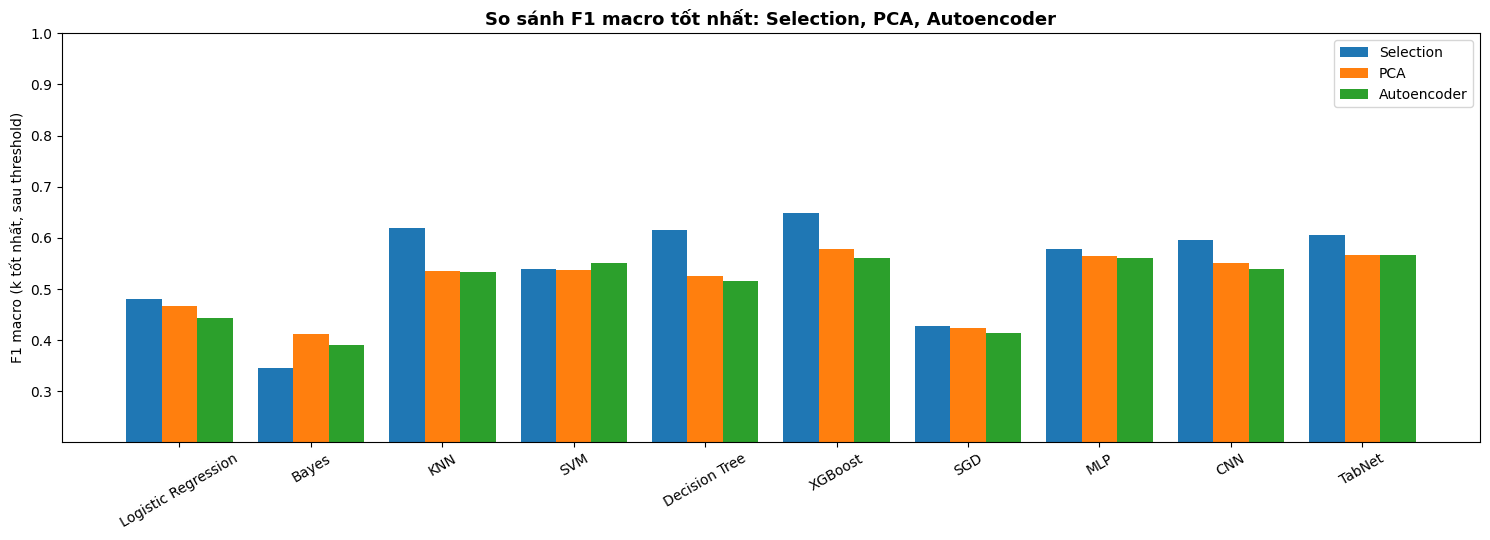

In [97]:
mau = {'Selection': '#1f77b4', 'PCA': '#ff7f0e', 'Autoencoder': '#2ca02c'}
x_pos = np.arange(len(bang_so_sanh))
w = 0.27

plt.figure(figsize=(15, 5.5))
for i, pp in enumerate(phuong_phap.keys()):
    plt.bar(x_pos + (i - 1) * w, bang_so_sanh[f'F1_{pp}'], w, label=pp, color=mau[pp])
plt.xticks(x_pos, bang_so_sanh['Mo_Hinh'], rotation=30)
plt.ylabel('F1 macro (k tốt nhất, sau threshold)')
plt.title('So sánh F1 macro tốt nhất: Selection, PCA, Autoencoder', fontsize=13, fontweight='bold')
plt.ylim(max(0, all_results['F1_Score'].min() - 0.05), 1.0)
plt.legend()
plt.tight_layout()
plt.show()

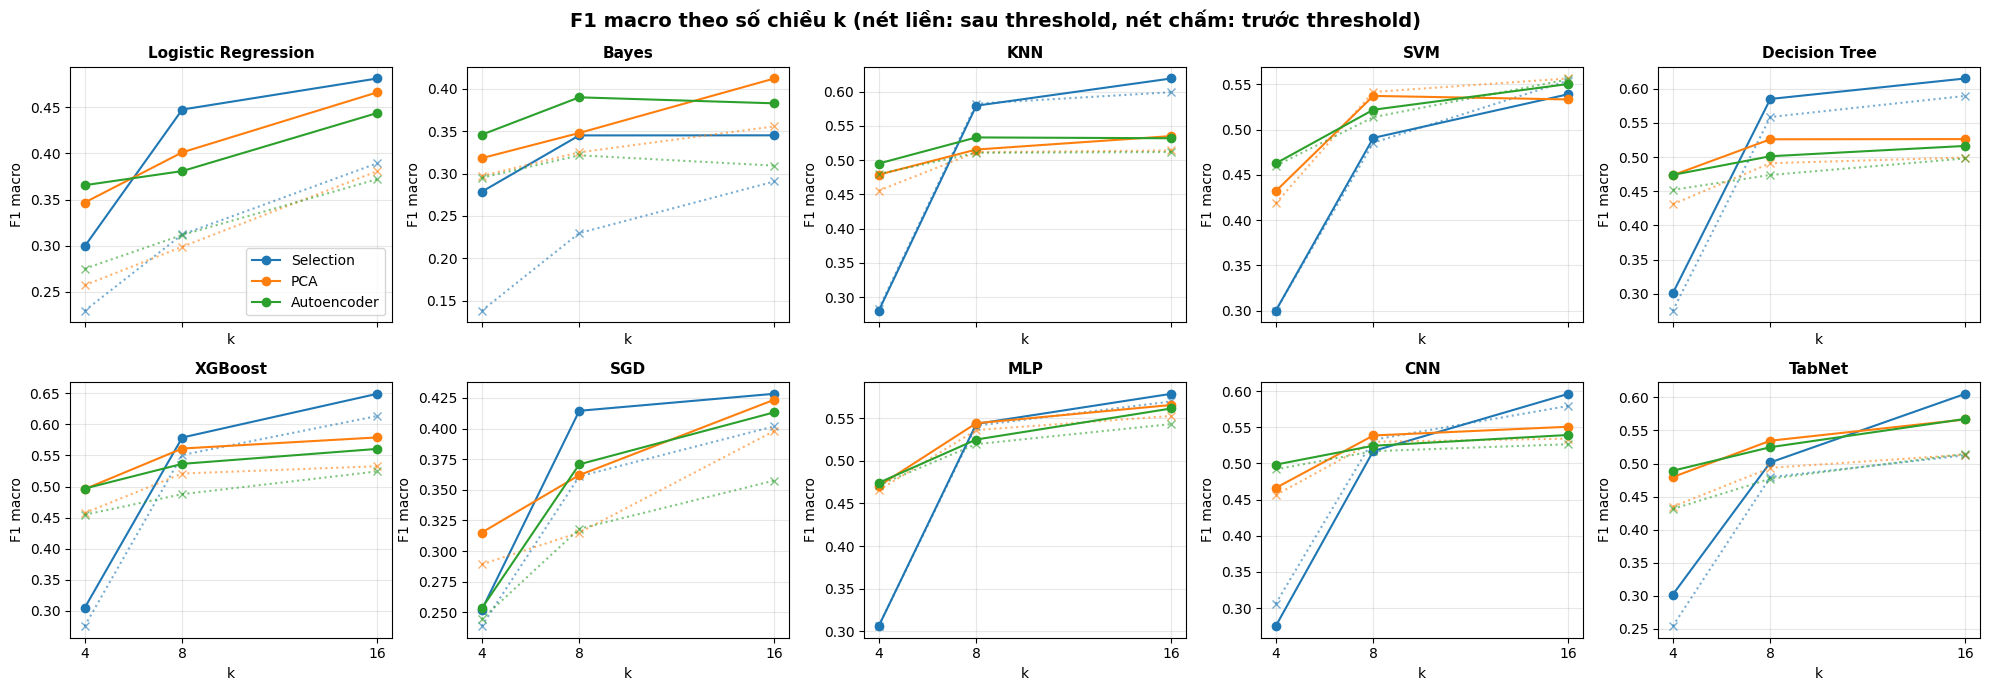

In [98]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
axes = axes.flatten()

for ax, ten in zip(axes, ten_mo_hinh.keys()):
    d = all_results[all_results['Mo_Hinh'] == ten]
    for pp in phuong_phap.keys():
        dd = d[d['Phuong_Phap'] == pp].sort_values('k')
        ax.plot(dd['k'], dd['F1_Score'], marker='o', label=pp, color=mau[pp])
        ax.plot(dd['k'], dd['F1_Goc'], marker='x', ls=':', color=mau[pp], alpha=0.6)
    ax.set_title(ten, fontsize=11, fontweight='bold')
    ax.set_xticks(K_LIST)
    ax.set_xlabel('k')
    ax.set_ylabel('F1 macro')
    ax.grid(alpha=0.3)

axes[0].legend()
plt.suptitle('F1 macro theo số chiều k (nét liền: sau threshold, nét chấm: trước threshold)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

4.6 Tổng kết

In [99]:
tong_ket = all_results.groupby('Phuong_Phap')[['Accuracy', 'Precision', 'Recall', 'F1_Goc', 'F1_Score', 'F1_Weighted', 'AUC', 'Train_Time_s', 'Infer_Time_ms']].mean().round(4)
print("Trung bình trên toàn bộ mô hình và k:")
print(tong_ket.to_string())

print()
print("Số mô hình mà mỗi phương pháp tốt nhất (theo F1 macro tốt nhất):")
print(bang_so_sanh['Tot_nhat'].value_counts().to_string())

best_overall = all_results.loc[all_results['F1_Score'].idxmax()]
print()
print(f"Cấu hình tốt nhất: {best_overall['Mo_Hinh']} | {best_overall['Phuong_Phap']} | k = {int(best_overall['k'])} | "
      f"F1 macro = {best_overall['F1_Score']} (trước threshold: {best_overall['F1_Goc']})")

Trung bình trên toàn bộ mô hình và k:
             Accuracy  Precision  Recall  F1_Goc  F1_Score  F1_Weighted     AUC  Train_Time_s  Infer_Time_ms
Phuong_Phap                                                                                                 
Autoencoder    0.7214     0.5030  0.5040  0.4406    0.4743       0.7363  0.8956       16.4565      4787.5427
PCA            0.7250     0.4977  0.5071  0.4454    0.4768       0.7405  0.9034       18.2822      4449.3847
Selection      0.7031     0.4843  0.4941  0.4113    0.4453       0.7182  0.8965       15.8940      4612.7753

Số mô hình mà mỗi phương pháp tốt nhất (theo F1 macro tốt nhất):
Tot_nhat
Selection      8
PCA            1
Autoencoder    1

Cấu hình tốt nhất: XGBoost | Selection | k = 16 | F1 macro = 0.6494 (trước threshold: 0.6136)


4.7 Chi tiết từng lớp của cấu hình tốt nhất

Threshold (bias) theo lớp: {'Analysis': 1.3, 'Backdoor': 0.97, 'DoS': 0.65, 'Exploits': 0.0, 'Fuzzers': 0.0, 'Generic': -0.65, 'Normal': -0.32, 'Reconnaissance': 0.32, 'Shellcode': 0.32, 'Worms': 0.97}

>> 16 feature được chọn (xếp theo độ quan trọng giảm dần):
    1. service_unknown            0.0717
    2. sttl                       0.0637
    3. proto_udp                  0.0634
    4. service_dns                0.0629
    5. ct_src_dport_ltm           0.0574
    6. service_http               0.0423
    7. smean                      0.0390
    8. dttl                       0.0370
    9. ct_dst_ltm                 0.0345
   10. sbytes                     0.0319
   11. dmean                      0.0301
   12. dload                      0.0285
   13. state_INT                  0.0270
   14. ct_dst_sport_ltm           0.0265
   15. dbytes                     0.0260
   16. ct_srv_src                 0.0238

                precision    recall  f1-score   support

      Analysis     0.458

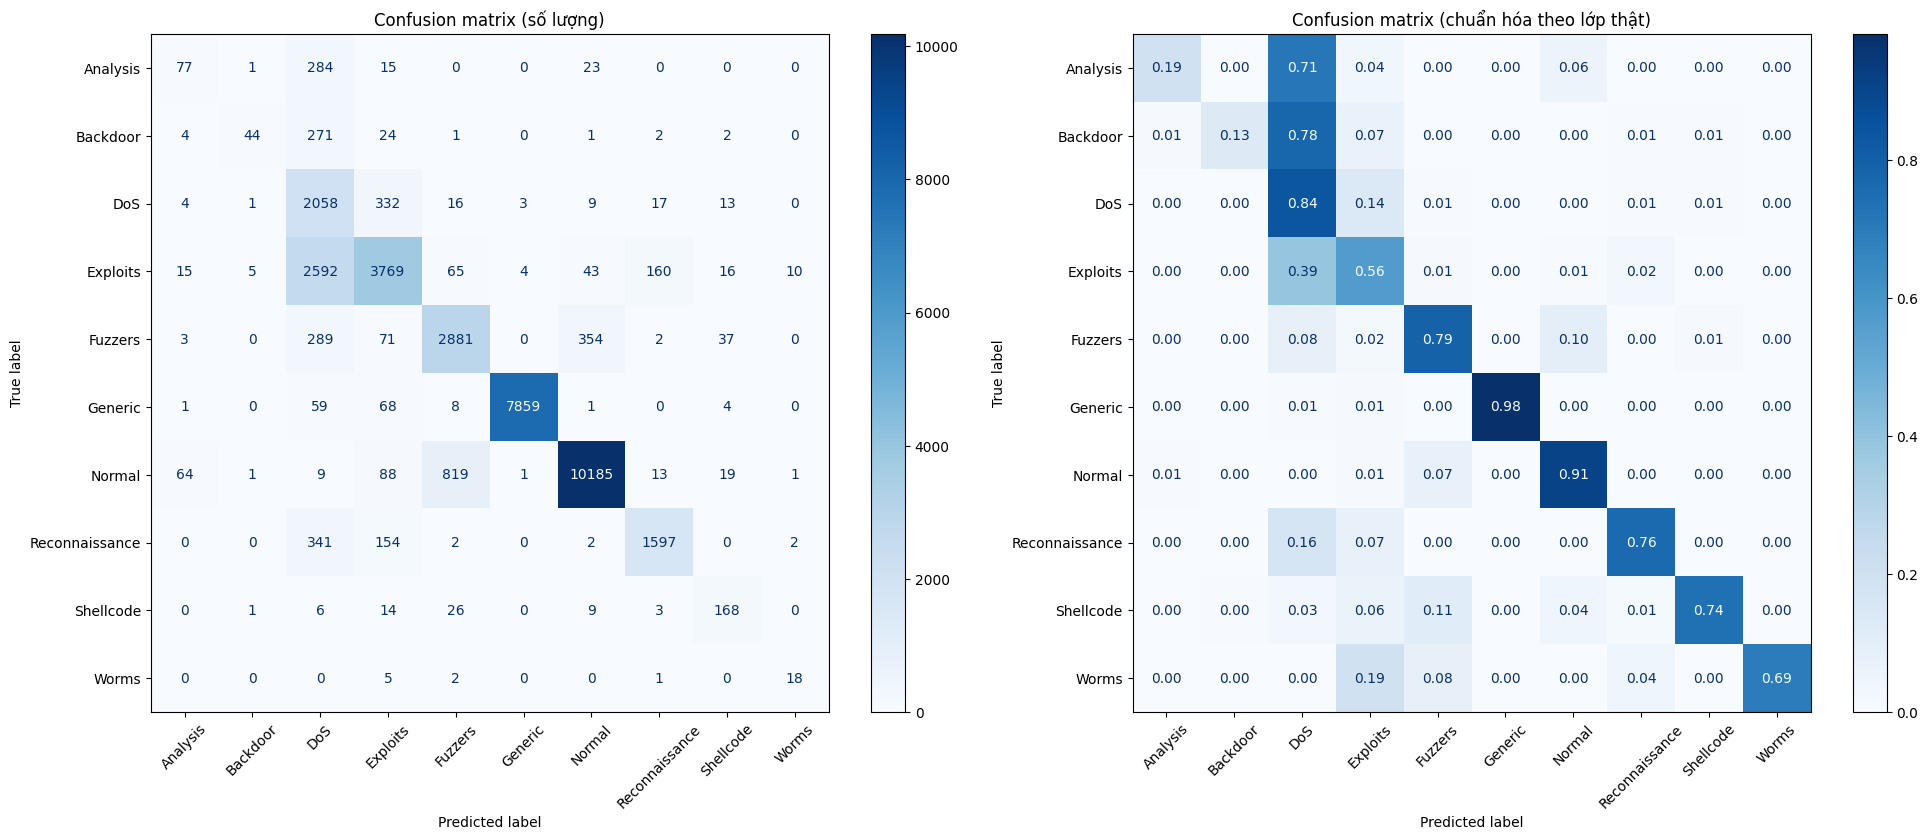

In [100]:
key = (phuong_phap[best_overall['Phuong_Phap']][0], ten_mo_hinh[best_overall['Mo_Hinh']], int(best_overall['k']))
y_pred_best = du_doan_luu[key]

print('Threshold (bias) theo lớp:', dict(zip(class_names, np.round(bias_luu[key], 2).tolist())))
if key[0] == 'sel':
    print()
    in_feature_chon(key[2])
print()
print(classification_report(y_test, y_pred_best, target_names=class_names, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names,
                                        xticks_rotation=45, cmap=plt.cm.Blues, values_format='d', ax=axes[0])
axes[0].set_title('Confusion matrix (số lượng)')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names, normalize='true',
                                        xticks_rotation=45, cmap=plt.cm.Blues, values_format='.2f', ax=axes[1])
axes[1].set_title('Confusion matrix (chuẩn hóa theo lớp thật)')
plt.tight_layout()
plt.show()